# Análise exploratória de dados

Esse notebook organiza nosso processo e nossos achados durante a fase de exploração dos dados do projeto; nós o criamos após termos feito boa parte da análise para fins de avaliação por parte dos professores.
Caso queiram olhar a versão original (bem mais desorganizada), ela se encontra em [`EDA/com_pedidos.ipynb`](EDA/com_pedidos.ipynb).

**Disclaimer**: durante o processo de exploração dos dados, nós acabamos não separando o conjunto de dados em treino, validação e teste, assim, fizemos a análise no conjunto completo. Pensávamos que o problema de vazamento de dados se limitava ao pré-processamento e não levamos em consideração que, ao analisar métricas relacionadas ao conjunto como um todo, a presença dos futuros dados de treino e validação poderia enviesar nossas conclusões com base em informações às quais não deveríamos ter acesso. Após conversarmos com o professor Paulo, decidimos incluir esse aviso por transparência e para registrar nosso aprendizado durante o projeto. Faremos essa ressalva novamente quando for relevante.

---

### Setup do notebook

Importando as dependências necessárias:

In [3]:
import pprint
import re

import matplotlib.pyplot as plot
import numpy as np
import pandas as pd
import seaborn as sb
from scipy import stats

# Configurando o estilo dos gráficos que criaremos:
sb.set_theme(style='ticks', palette='Set2')

Vamos carregar os dados fornecidos agora.

In [4]:
leads = pd.read_csv('data/churn_aplicacao_leads_final.csv')
pedidos = pd.read_csv('data/churn_comportamental_pedidos_final.csv')

Iremos também efetuar um "join" para cruzar os dados dos pedidos com os clientes na tabela de leads fornecida:

In [5]:
clientes_com_pedidos = leads.merge(right=pedidos, on='id_cliente', how='left')

---


## 1. Análise estrutural

Usaremos o método `info()` nos DataFrames para ter uma visão geral dos dados:

In [6]:
leads.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id_cliente                       2000 non-null   int64  
 1   uf                               2000 non-null   str    
 2   municipio                        2000 non-null   str    
 3   segmento_cliente                 2000 non-null   str    
 4   natureza_juridica                2000 non-null   str    
 5   fonte_cliente                    2000 non-null   str    
 6   cnae_codigo                      2000 non-null   str    
 7   capital_social                   2000 non-null   str    
 8   idade_cnpj                       2000 non-null   str    
 9   serasa_contagem_negativacoes     2000 non-null   float64
 10  serasa_contagem_protestos        2000 non-null   float64
 11  serasa_credores                  190 non-null    str    
 12  serasa_socio_tem_negativacao   

- Temos 2000 amostras nessa tabela.
- Existem 19 atributos, a maioria dos quais aparenta ser categórico.
- Os seguintes campos aparentam ter dados faltantes:
    - `serasa_credores`;
    - `ifood_contagem_avaliacoes`;
    - `ifood_faixa_preco`;
    - `google_maps_avaliacao`;
    - `google_maps_contagem_avaliacoes`; e
    - `google_maps_tem_website`.
- Fora esses valores que devemos averiguar, todos os outros parecem estar completos, basta verificar se as amostras são únicas mesmo.

In [7]:
pedidos.info()

<class 'pandas.DataFrame'>
RangeIndex: 4441 entries, 0 to 4440
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id_pedido     4441 non-null   int64
 1   id_cliente    4441 non-null   int64
 2   valor         4438 non-null   str  
 3   produtos      4440 non-null   str  
 4   data_entrega  4441 non-null   str  
dtypes: int64(2), str(3)
memory usage: 173.6 KB


- Temos uma tabela com bem menos atributos, uma vez que 2 dos 5 são identificadores.
- Existem muito mais pedidos que clientes, mas esses pedidos são de clientes diferentes ou são vários de um cliente só?
- `valor` e `produtos` têm alguns valores faltantes.
- `data_entrega` deve representar uma data, apesar do tipo inferido pelo pandas ser `str`.
    - Significa dizer que o comportamento dos clientes é registrado em uma série temporal.

Vamos entender se os pedidos são diversos entre os clientes registrados.

In [8]:
print(f'Quantidade de clientes sem pedidos: {clientes_com_pedidos.id_pedido.isna().sum()}\n')

print('Quantidade de pedidos por cliente (>0):')
pedidos.id_cliente.value_counts()

Quantidade de clientes sem pedidos: 1000

Quantidade de pedidos por cliente (>0):


id_cliente
1739936841220    56
8113331192324    46
7243866379881    44
1560063946241    29
1222295907587    29
                 ..
5670680913506     1
1834318012896     1
5283377970744     1
1749787686127     1
9798908632848     1
Name: count, Length: 1000, dtype: int64

Tudo indica que é relativamente diverso, definitivamente não há o problema de apenas um cliente ter a maioria dos pedidos.

O objetivo do nosso futuro modelo será prever a probabilidade de um cliente dar churn, logo `churned` é nosso atributo-alvo.

Vamos ver a quantidade de amostras da tabela de **leads** com `churned == 0` e `churned == 1`:

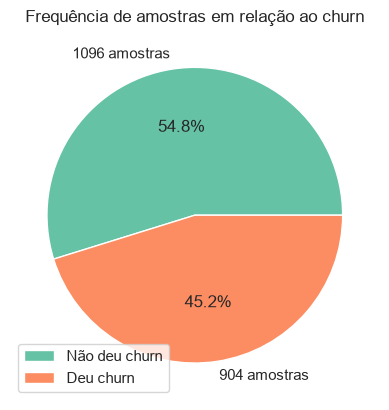

In [9]:
contagem_de_churned = leads.churned.value_counts()

plot.title('Frequência de amostras em relação ao churn')
plot.pie(contagem_de_churned, labels=[f'{contagem} amostras' for contagem in contagem_de_churned], autopct='%.1f%%')
plot.legend(['Não deu churn', 'Deu churn'])
plot.show()

Existem mais clientes que não deram churn que o contrário, mas não a ponto de termos pouquíssimos exemplos.

Vamos ver agora quais são os valores possíveis para cada atributo nos conjuntos:

In [10]:
def print_unique_count(table: pd.DataFrame, table_name: str, max_count: int = 20):
    print(f'Valores únicos dos atributos de {table_name}:')

    for label in table.columns:
        column: pd.Series = table[label]

        unique_values = column.unique()
        print(f'{label:32s} | {unique_values.size!s:5s}', end='')

        # Imprimindo os valores possíveis para
        # os atributos somente se são poucos:
        if unique_values.size <= max_count:
            values_str = ', '.join(str(v) for v in unique_values)
            print(f'({values_str})', end='')

        print()

print_unique_count(leads, 'leads', max_count=32)
print()
print_unique_count(pedidos, 'pedidos')

Valores únicos dos atributos de leads:
id_cliente                       | 2000 
uf                               | 1    (CE)
municipio                        | 31   (FORTALEZA, MARACANAU, CAUCAIA, AQUIRAZ, EUSEBIO, PINDORETAMA, HORIZONTE, MARANGUAPE, CASCAVEL, PACAJUS, PACATUBA, SAO GONCALO DO AMARANTE, ITAITINGA, REDENCAO, GUAIUBA, ARACOIABA, ACARAPE, CHOROZINHO, BATURITE, PACOTI, GUARAMIRANGA, PARACURU, ARACATI, PARAIPABA, AMONTADA, BARREIRA, TURURU, PALMACIA, BARBARA BEATRIZ QUEIROZ DE SOUSA 60464662370, JIJOCA DE JERICOACOARA, CRUZ)
segmento_cliente                 | 21   (Segmento 5, Segmento 19, Segmento 20, Segmento 13, Segmento 18, Segmento 14, Segmento 3, Segmento 10, Segmento 15, Segmento 4, Segmento 16, Segmento 8, Segmento 6, Segmento 9, Segmento 17, Segmento 2, Segmento 21, Segmento 7, Segmento 1, Segmento 11, Segmento 12)
natureza_juridica                | 4    (206-2 - Sociedade Empresária Limitada, 213-5 - Empresário (Individual), 230-5 - Empresa Individual de Responsab

- **O atributo `uf` é irrelevante**, pois todos os dados do nosso conjunto são de apenas um estado. Devemos descartá-lo na fase de pré-processamento.
- Boa parte dos valores são categóricos, com a maioria desses sendo intervalos de valores bem ordenados.
- O atributo `google_maps_tem_website` é uma flag booleana que representa `true` como `1` e `false` como `nan`.

Olhamos também os valores únicos para `serasa_credores`:

In [11]:
serasa_credores_unicos = leads.serasa_credores.dropna().unique()

print('Valores únicos para o atributo serasa_credores:')
pprint.pp(sorted(serasa_credores_unicos))

Valores únicos para o atributo serasa_credores:
['Alimentos e Bebidas',
 'Alimentos e Bebidas, Alimentos e Bebidas, Alimentos e Bebidas',
 'Alimentos e Bebidas, Bancos e Financeiro',
 'Alimentos e Bebidas, Bancos e Financeiro, Alimentos e Bebidas',
 'Alimentos e Bebidas, Bancos e Financeiro, Bancos e Financeiro, Financeiro, '
 'Alimentos e Bebidas, Alimentos e Bebidas, Indústria',
 'Alimentos e Bebidas, Saúde',
 'Alimentos e Bebidas, Tecnologia e Pagamentos',
 'Bancos e Financeiro',
 'Bancos e Financeiro, Alimentos e Bebidas, Bancos e Financeiro',
 'Bancos e Financeiro, Alimentos e Bebidas, Distribuição',
 'Bancos e Financeiro, Bancos e Financeiro',
 'Bancos e Financeiro, Bancos e Financeiro, Bancos e Financeiro',
 'Bancos e Financeiro, Bancos e Financeiro, Telecomunicações, Contabilidade',
 'Bancos e Financeiro, Comunicação',
 'Bancos e Financeiro, Financeiro',
 'Bancos e Financeiro, Tecnologia e Pagamentos',
 'Bancos e Financeiro, Tecnologia e Pagamentos, Bancos e Financeiro',
 'Comu

Como os valores dessa coluna são listas separadas por vírgulas, alguns tem 'e' no próprio nome, mas o separador real é apenas a vírgula. Podemos consultar os *tipos de credor* únicos da seguinte forma:

In [12]:
tipos_credores_unicos: set[str] = set()
for lista_credores in serasa_credores_unicos:
    tipos_credores_unicos.update(lista_credores.split(', '))

print('Tipos de credores únicos registrados no atributo serasa_credores:')
pprint.pp(tipos_credores_unicos)

Tipos de credores únicos registrados no atributo serasa_credores:
{'Alimentos e Bebidas',
 'Bancos e Financeiro',
 'Comunicação',
 'Comércio',
 'Contabilidade',
 'Distribuição',
 'Diversos',
 'Energia',
 'Financeiro',
 'Imobiliário',
 'Indústria',
 'Logística',
 'Saúde',
 'Seguros e Financeiro',
 'Serviços',
 'Serviços Ambientais',
 'Tecnologia',
 'Tecnologia e Pagamentos',
 'Telecomunicações',
 'Varejo',
 'Viagens e Turismo'}


Vamos verificar quais são as porcentagens de faltas nos atributos observados anteriormente:

In [13]:
def print_missing_pct(table: pd.DataFrame, table_name: str):
    print(f'Porcentagem de faltas nos atributos de {table_name}:')

    for label in table.columns:
        column: pd.Series = table[label]
        missing_pct = 100 * column.isna().sum() / column.size
        
        if missing_pct > 0:
            print(f'{label:32s} | {missing_pct:.2f}% ({column.isna().sum()}/{column.size})')

print_missing_pct(leads, 'leads')
print()
print_missing_pct(pedidos, 'pedidos')

Porcentagem de faltas nos atributos de leads:
serasa_credores                  | 90.50% (1810/2000)
ifood_contagem_avaliacoes        | 94.30% (1886/2000)
ifood_faixa_preco                | 87.85% (1757/2000)
google_maps_avaliacao            | 97.80% (1956/2000)
google_maps_contagem_avaliacoes  | 91.25% (1825/2000)
google_maps_tem_website          | 91.25% (1825/2000)

Porcentagem de faltas nos atributos de pedidos:
valor                            | 0.07% (3/4441)
produtos                         | 0.02% (1/4441)


Vamos observar primeiro a tabela de **leads**:
- Pelo documento no Notion, os valores de `serasa_credores` são listas separadas por vírgulas dos tipos de credores do cliente. Ou seja, ter um valor nulo de `serasa_credores` implica não ter nenhum credor, assim, a falta do valor tem uma semântica bem definida.
- Os atributos `ifood_contagem_avaliacoes` e `ifood_faixa_preco` são nulos se o cliente não possui nenhuma conta no iFood. Pelo o que entendemos, a Praso não atende exclusivamente restaurantes, mas também fornecem seus serviços para outros comércios que não são comuns no iFood (como supermercados, já que apenas as grandes cadeias têm entregas pelo iFood), logo, esses atributos não trazem muitas informações sobre a população como um todo. Podem valer a pena manter se tiverem uma grande correlação com o atributo-alvo, mas se não tiverem, talvez seja mais relevante apenas saber se o cliente tem iFood ou não.
- As faltas no atributo `google_maps_tem_website` têm semântica clara como visto anteriormente. Ademais, se o estabelecimento não está registrado no Google Maps, terá 0 avaliações. O intervalo desse atributo de menores fronteiras é `(0, 5]`, o qual não inclui diretamente o número 0. Se formos usar esse atributo, podemos usar desse fato para criar uma nova categoria. 
- Além disso, `google_maps_avaliacao` tem valor em apenas 2.2% das amostras (a menor quantidade de todas), e a falta desses valores não tem semântica clara. Pela falta de dados, isso pode inviablizar seu uso no modelo.

A tabela de **pedidos** tem pouquíssimos valores faltantes. Nós acabamos vendo as amostras que tinham esses valores faltantes (note que sabemos que, do jeito que fizemos, **isso não é uma boa ideia**, vide o disclaimer):

In [14]:
pedidos[pedidos.valor.isna() | pedidos.produtos.isna()]

,id_pedido,id_cliente,valor,produtos,data_entrega
1754,3651192517370,5284965822687,NaN,"(0, 5]",2024-11-07
3566,8540620592324,6829726356717,NaN,"(0, 5]",2024-10-06
3603,9279195172130,8400679696018,NaN,NaN,2024-09-10


Pela pouca quantidade, e sabendo dos valores possíveis para `valor` e `produtos` (são categóricos), podemos imputar potenciais valores faltantes nessas colunas usando a **moda** dos valores correspondentes dos pedidos feitos pelo cliente. **Levaremos isso em conta somente quando separarmos os conjuntos e partimos para o pré-processamento dos dados.**

Por fim, analisamos a temporalidade da tabela de pedidos, vendo em qual intervalo de tempo o conjunto registrou amostras:

In [15]:
primeira_data = pedidos.data_entrega.min()
ultima_data = pedidos.data_entrega.max()

print(f'Intervalo de tempo: {primeira_data} ---- {ultima_data}')

Intervalo de tempo: 2024-09-01 ---- 2024-12-01


Como confirmado pela Praso, os dados se referem ao último trimestre de 2024.

---

## 2. Análise univariada


Vamos tentar compreender melhor a distribuição de cada atributo, separando a análise em duas partes: primeiro o **perfil cadastral dos leads** (2.1) e depois o **comportamento de pedidos** (2.2).

Começamos pelos atributos categóricos que armazenam intervalos de valores numéricos. Criamos duas funções auxiliares: uma para ordenar esses intervalos corretamente e outra para plotar dois atributos desse tipo lado a lado.


In [16]:
def sort_by_range(values: list[str], *, is_float = False):
    """Ordena intervalos numéricos escritos por extenso"""

    range_type = float if is_float else int
    
    ranges = sorted(
        [range_type(v) for v in range[1:-1].split(', ')]
        for range in values
    )

    return [
        f'({a}, {b}]' for a, b in ranges
    ]

In [17]:
def plot_ranged_countplot1x2(data: pd.DataFrame, features: tuple[str, str], show_avg_count: bool = False):
    axes = plot.figure(figsize=(20, 10)).subplots(1, 2)

    for i in range(2):
        feature, ax = features[i], axes[i % 2]
        is_float = feature in ('google_maps_avaliacao') # só esse atributo tem intervalo em floats

        ranges = sort_by_range(data[feature].dropna().unique(), is_float=is_float)
        sb.countplot(
            data=data,
            y=feature,
            order=ranges,
            ax=ax
        )
        if show_avg_count:
            ax.plot(
                [data[feature].value_counts().mean() for _ in ranges],
                ranges,
                linestyle='--',
                color='black',
            )
            ax.legend(['Contagem média'])

### 2.1 Perfil dos leads

Analisamos a distribuição dos atributos cadastrais da tabela de leads.


#### Capital social e idade do CNPJ


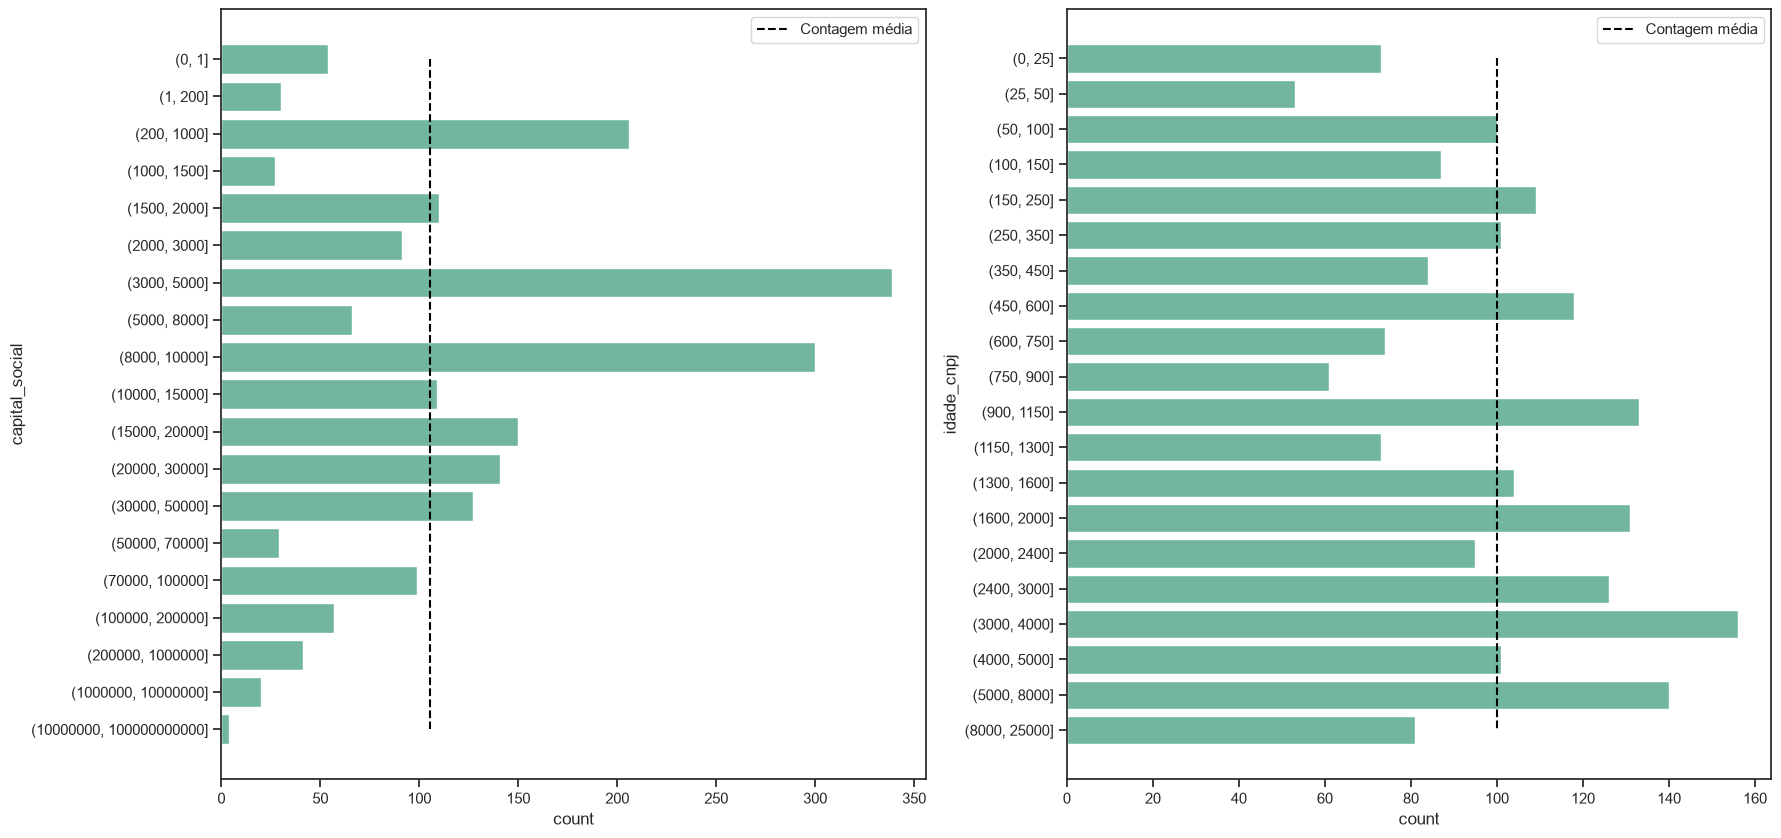

In [18]:
plot_ranged_countplot1x2(leads, ('capital_social', 'idade_cnpj'), show_avg_count=True)

Vemos que os clientes no conjunto têm uma boa diversidade no que tange ao capital social e à idade do CNPJ; em ambos atributos, temos categorias com valores abaixo e acima da média por margens significativas.

Em geral, os clientes registrados tem capital social na faixa de 3000 a 10000 e os seus CNPJs tendem a ser um pouquinho mais velhos que novos.

#### Avaliações no Google Maps e no iFood


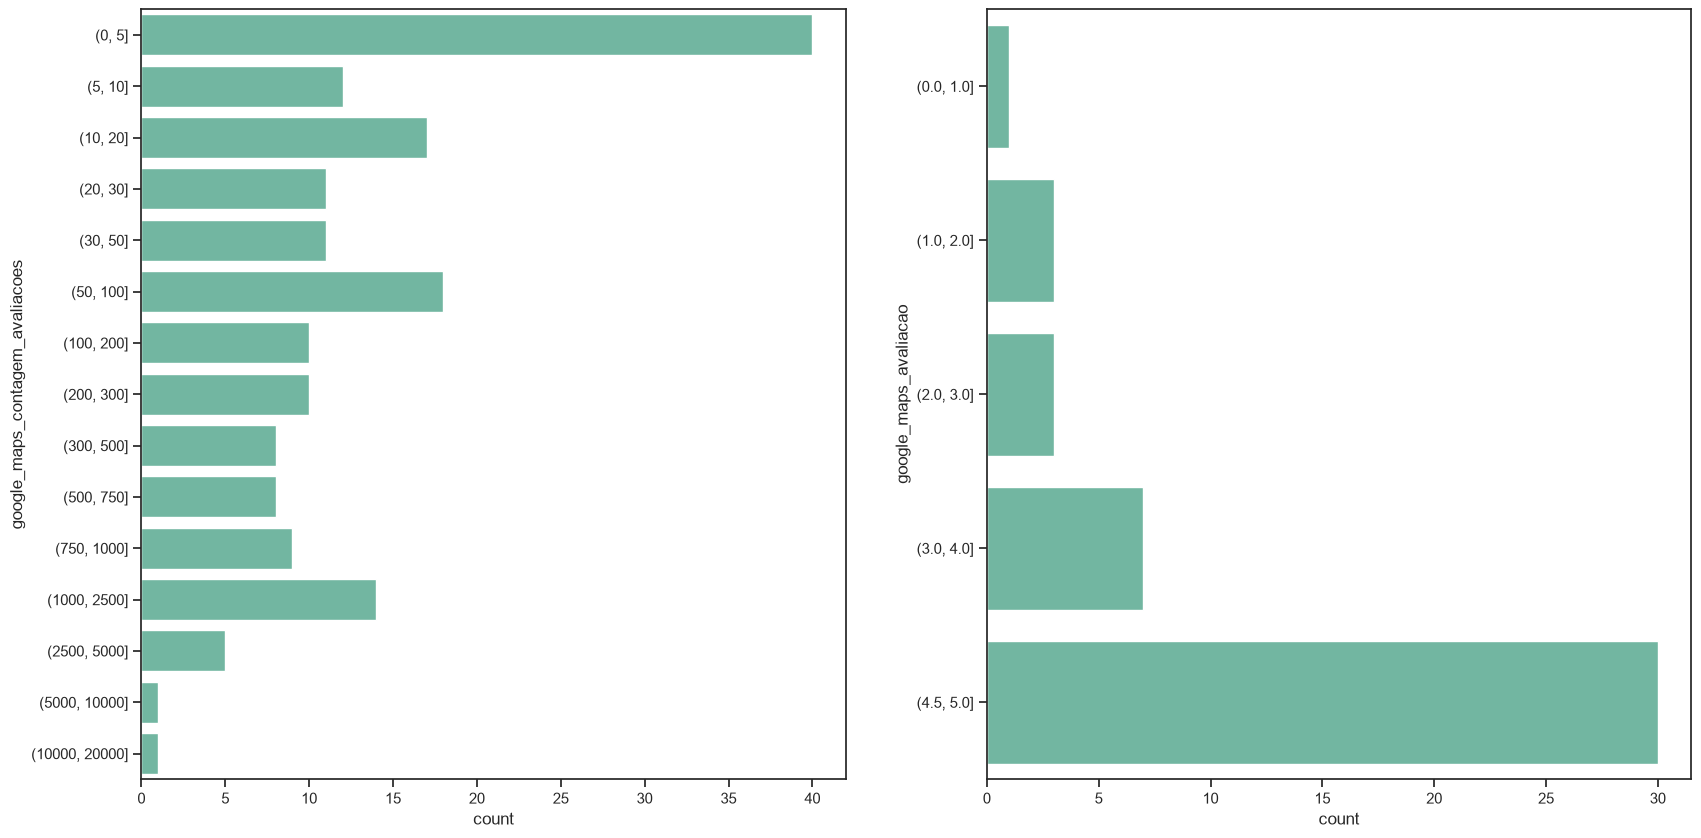

In [19]:
plot_ranged_countplot1x2(leads, ('google_maps_contagem_avaliacoes', 'google_maps_avaliacao'))

Em relação aos poucos clientes que têm cadastro no Google Maps, há um padrão mais claro. Os estabelecimentos que têm website no Google Maps tendem a ser mais bem avaliados, mas não têm muitas avaliações. Isso pode significar que a avaliação registrada não é o consenso exato de todos os usuários do serviço do cliente, e talvez para alguns a avaliação diminuiria se mais pessoas as fizessem no Google Maps.

<Axes: xlabel='count', ylabel='ifood_contagem_avaliacoes'>

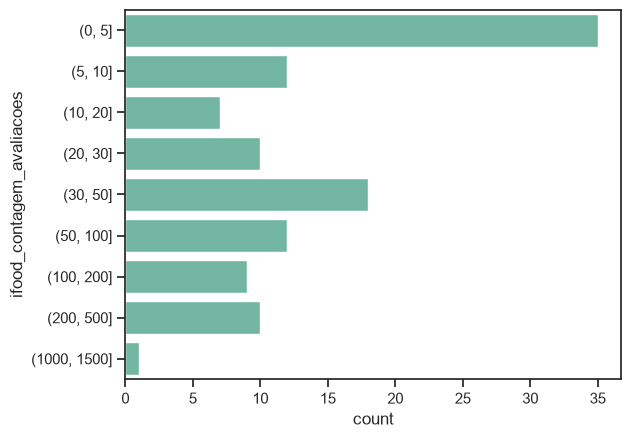

In [20]:
sb.countplot(
    data=leads,
    y='ifood_contagem_avaliacoes',
    order=sort_by_range(leads.ifood_contagem_avaliacoes.dropna().unique()),
)

Já no que tange à contagem de avaliações no iFood, o padrão é similar àquele observado na contagem do Google Maps, já que de fato consumidores tendem a dar poucas avaliações.

#### Fonte e segmento do cliente


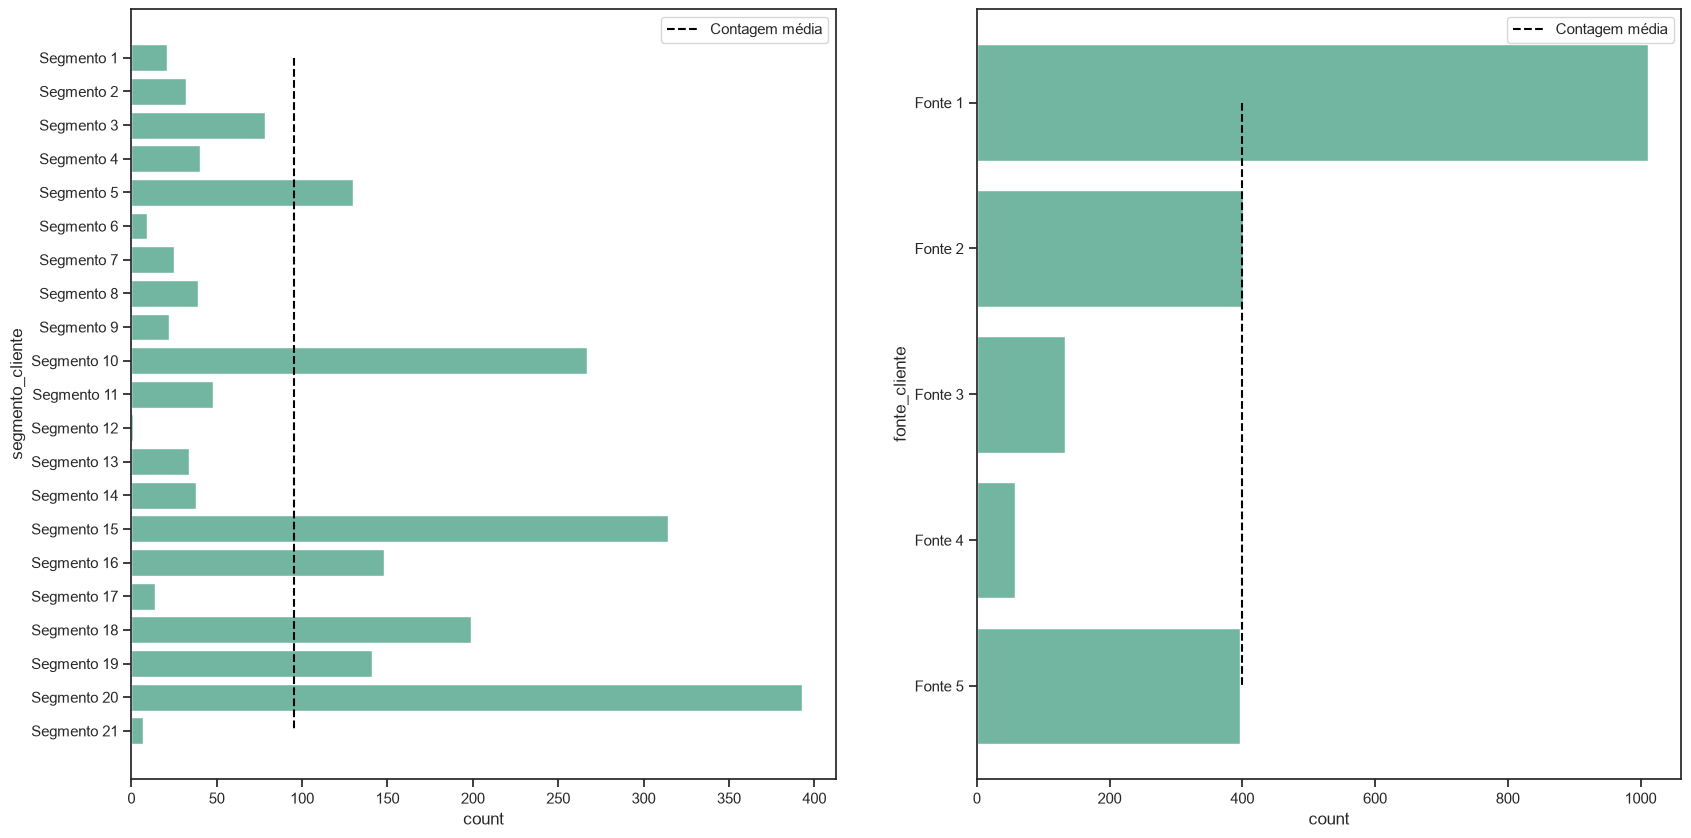

In [21]:
get_number = lambda str: str.split(' ')[1]
segmentos = leads.segmento_cliente.sort_values(key=lambda arr: [int(get_number(elem)) for elem in arr])
fontes = leads.fonte_cliente.sort_values(key=lambda arr: [int(get_number(elem)) for elem in arr])

ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

sb.countplot(data=segmentos, ax=ax1)
ax1.plot(
    [segmentos.value_counts().mean() for _ in segmentos.unique()],
    segmentos.unique(),
    linestyle='--',
    color='black',
)
ax1.legend(['Contagem média'])

sb.countplot(data=fontes, ax=ax2)
ax2.plot(
    [fontes.value_counts().mean() for _ in fontes.unique()],
    fontes.unique(),
    linestyle='--',
    color='black',
)
ax2.legend(['Contagem média'])

Em comparação com as variáveis de idade do CNPJ e de capital social, essas duas features apresentam muito mais variabilidade na contagem de suas categorias.

Os segmentos dos clientes são em sua grande maioria os 20, 15 e 10, com segmentos como o 12 tendo praticamente nenhuma amostra. Podemos agrupar alguns desses segmentos de baixa representatividade no futuro. Já a fonte do cliente é majoritariamente a 1, com as fontes 3 e 4 tendo baixíssima representatividade.

#### Natureza jurídica


<Axes: xlabel='count', ylabel='natureza_juridica'>

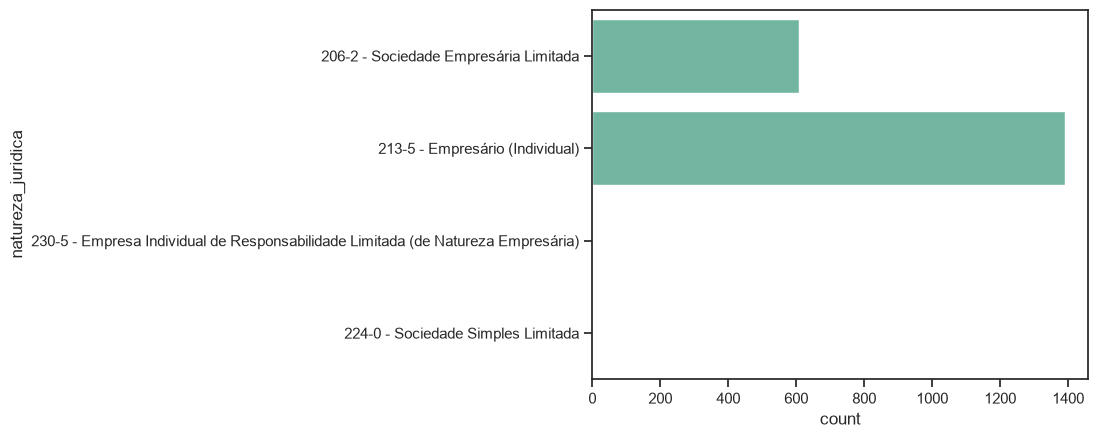

In [22]:
sb.countplot(data=leads.natureza_juridica)

A natureza jurídica apresenta uma variabilidade ainda maior: em geral, clientes são empresários individuais ou são parte de uma sociedade. Dessa forma, podemos agrupar as categorias `230-5` e `213-5`, e as categorias `206-2` e `224-0`, a partir dessa característica em comum para simplificar nosso trabalho durante o pré-processamento.

#### Faixa de preço no iFood

O atributo `ifood_faixa_preco` indica a faixa de preço dos estabelecimentos presentes no iFood, de `$` (mais barato) a `$$$$$` (mais caro). Por ser nulo para quem não está na plataforma, ele só existe para uma parcela dos leads.

<Axes: xlabel='count', ylabel='ifood_faixa_preco'>

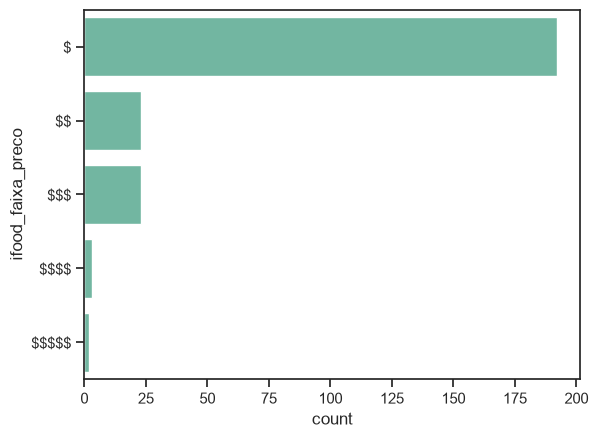

In [23]:
sb.countplot(data=leads.ifood_faixa_preco.dropna().sort_values().map(lambda str: str.replace('$', '\\$')))

Apenas cerca de 250 dos 2000 leads estão no iFood. Entre eles, a faixa `$` ocupa quase que a totalidade da amostra, `$$` e `$$$` cerca de 20 cada, e `$$$$` e `$$$$$` são próximas a 0. As faixas mais altas têm amostras pequenas demais para qualquer conclusão isolada.

#### Presença de website no Google Maps


<Axes: xlabel='google_maps_tem_website', ylabel='count'>

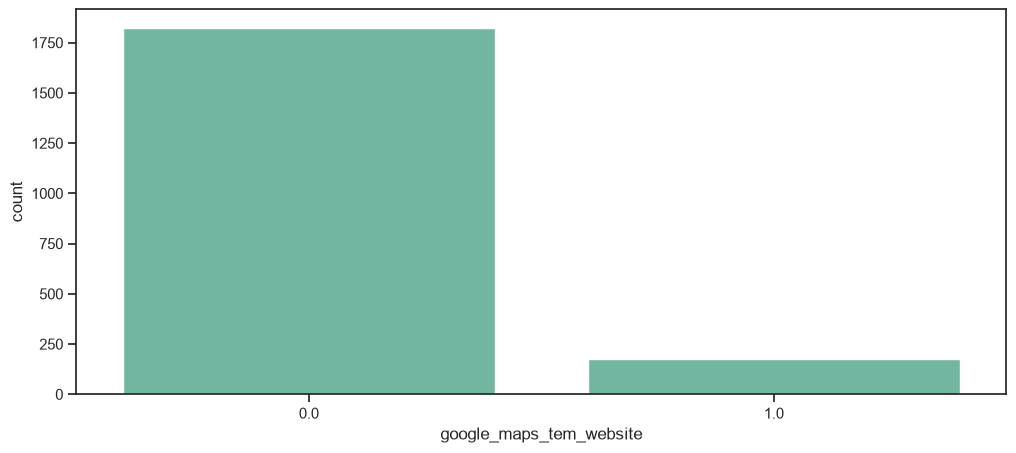

In [24]:
ax1 = plot.figure(figsize=(12, 5)).subplots(1, 1)

sb.countplot(x=leads.google_maps_tem_website.fillna(0), ax=ax1)


`google_maps_tem_website` é uma flag: uma pequena quantidade das leads têm valor (1), e os demais são nulos, que interpretamos como "não tem website". 

#### Município


In [25]:
def agrupa_raras(serie, minimo=30, nome='Outras'):
    contagem = serie.value_counts()
    return serie.where(serie.map(contagem) >= minimo, nome)

<Axes: xlabel='regiao', ylabel='count'>

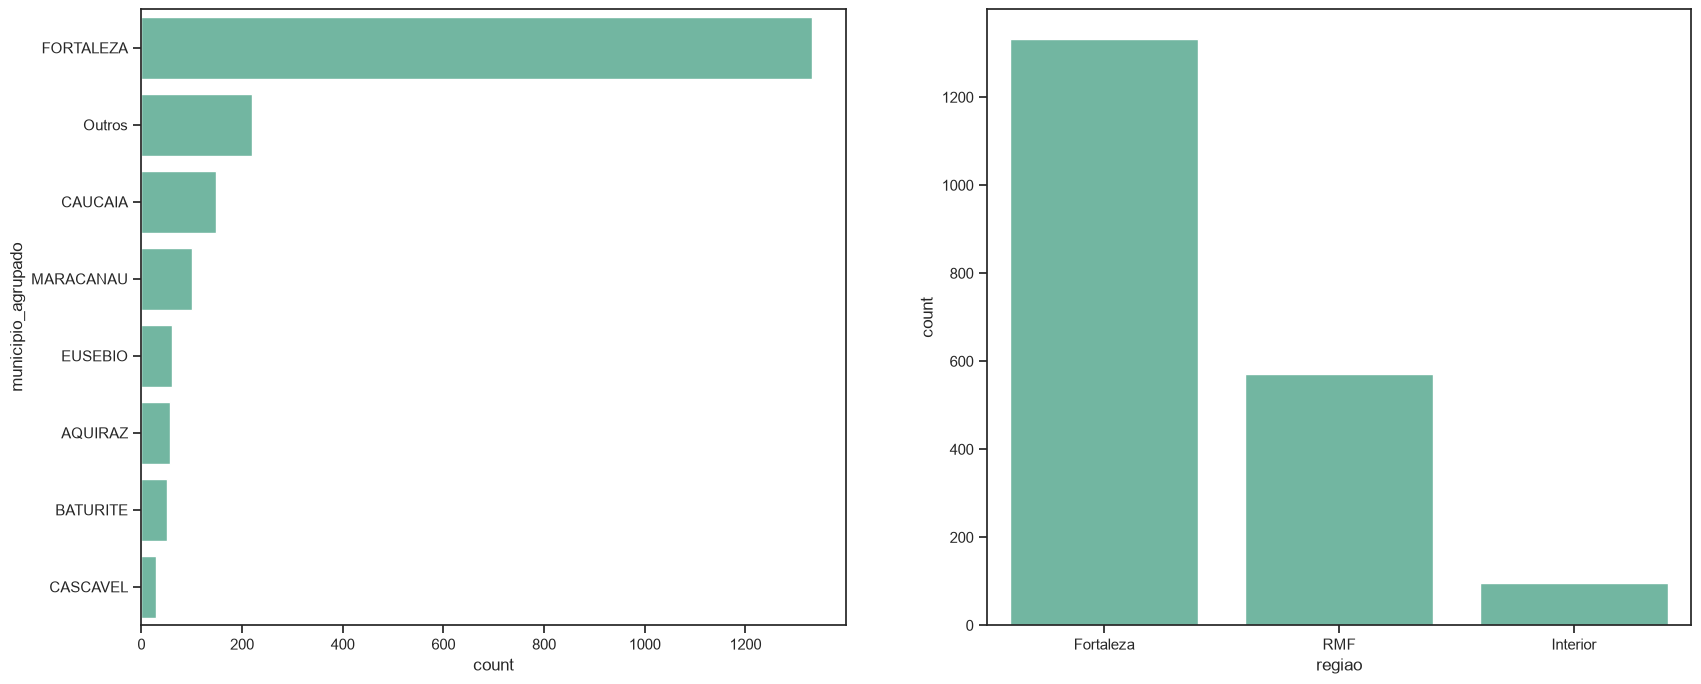

In [26]:
RMF = ['CAUCAIA', 'MARACANAU', 'MARANGUAPE', 'PACATUBA', 'ITAITINGA', 'EUSEBIO', 'AQUIRAZ', 'GUAIUBA', 'HORIZONTE',
       'PACAJUS', 'CHOROZINHO', 'SAO GONCALO DO AMARANTE', 'PINDORETAMA', 'CASCAVEL', 'PARACURU', 'PARAIPABA',
       'TRAIRI', 'SAO LUIS DO CURU']

leads['municipio_agrupado'] = agrupa_raras(leads['municipio'], nome='Outros')
leads['regiao'] = np.select([leads['municipio'] == 'FORTALEZA', leads['municipio'].isin(RMF)], ['Fortaleza', 'RMF'], 'Interior')

ax1, ax2 = plot.figure(figsize=(20, 8)).subplots(1, 2)
sb.countplot(data=leads, y='municipio_agrupado', order=leads.municipio_agrupado.value_counts().index, ax=ax1)
sb.countplot(data=leads, x='regiao', order=['Fortaleza', 'RMF', 'Interior'], ax=ax2)


`municipio` tem 31 valores distintos e é bastante concentrado: Fortaleza tem 1333 dos 2000 leads, a Região Metropolitana (RMF) 570 e o interior 97. Depois de Fortaleza, os maiores são Caucaia, Maracanaú, Eusébio, Aquiraz e Baturité. Os municípios com menos de 30 leads somam 220 e foram agrupados em "Outros". Um dos 31 valores não é um município (contém um nome de pessoa seguido de um número), o que indica erro de preenchimento a ser tratado no pré-processamento.

#### CNAE


O `CNAE` tem 107 códigos distintos, no formato AA.BC-C-DD (divisão > grupo > classe > subclasse). Os códigos foram anonimizados: alguns, como 12.10-3-97, não existem no CNAE 2.3 do IBGE, então os valores não têm significado explícito. Confirmamos com a monitoria que a troca é consistente (toda divisão igual vira o mesmo número), portanto a hierarquia continua válida.

exemplos de alguns códigos: ['12.10-3-97', '12.74-7-12', '12.74-7-32', '12.74-7-79', '14.17-3-90']


,categorias,categorias com >= 30 leads,leads nessas categorias
cnae_divisao,27,4,1909
cnae_grupo,60,7,1774
cnae_classe,77,7,1749
cnae_subclasse,107,13,1717


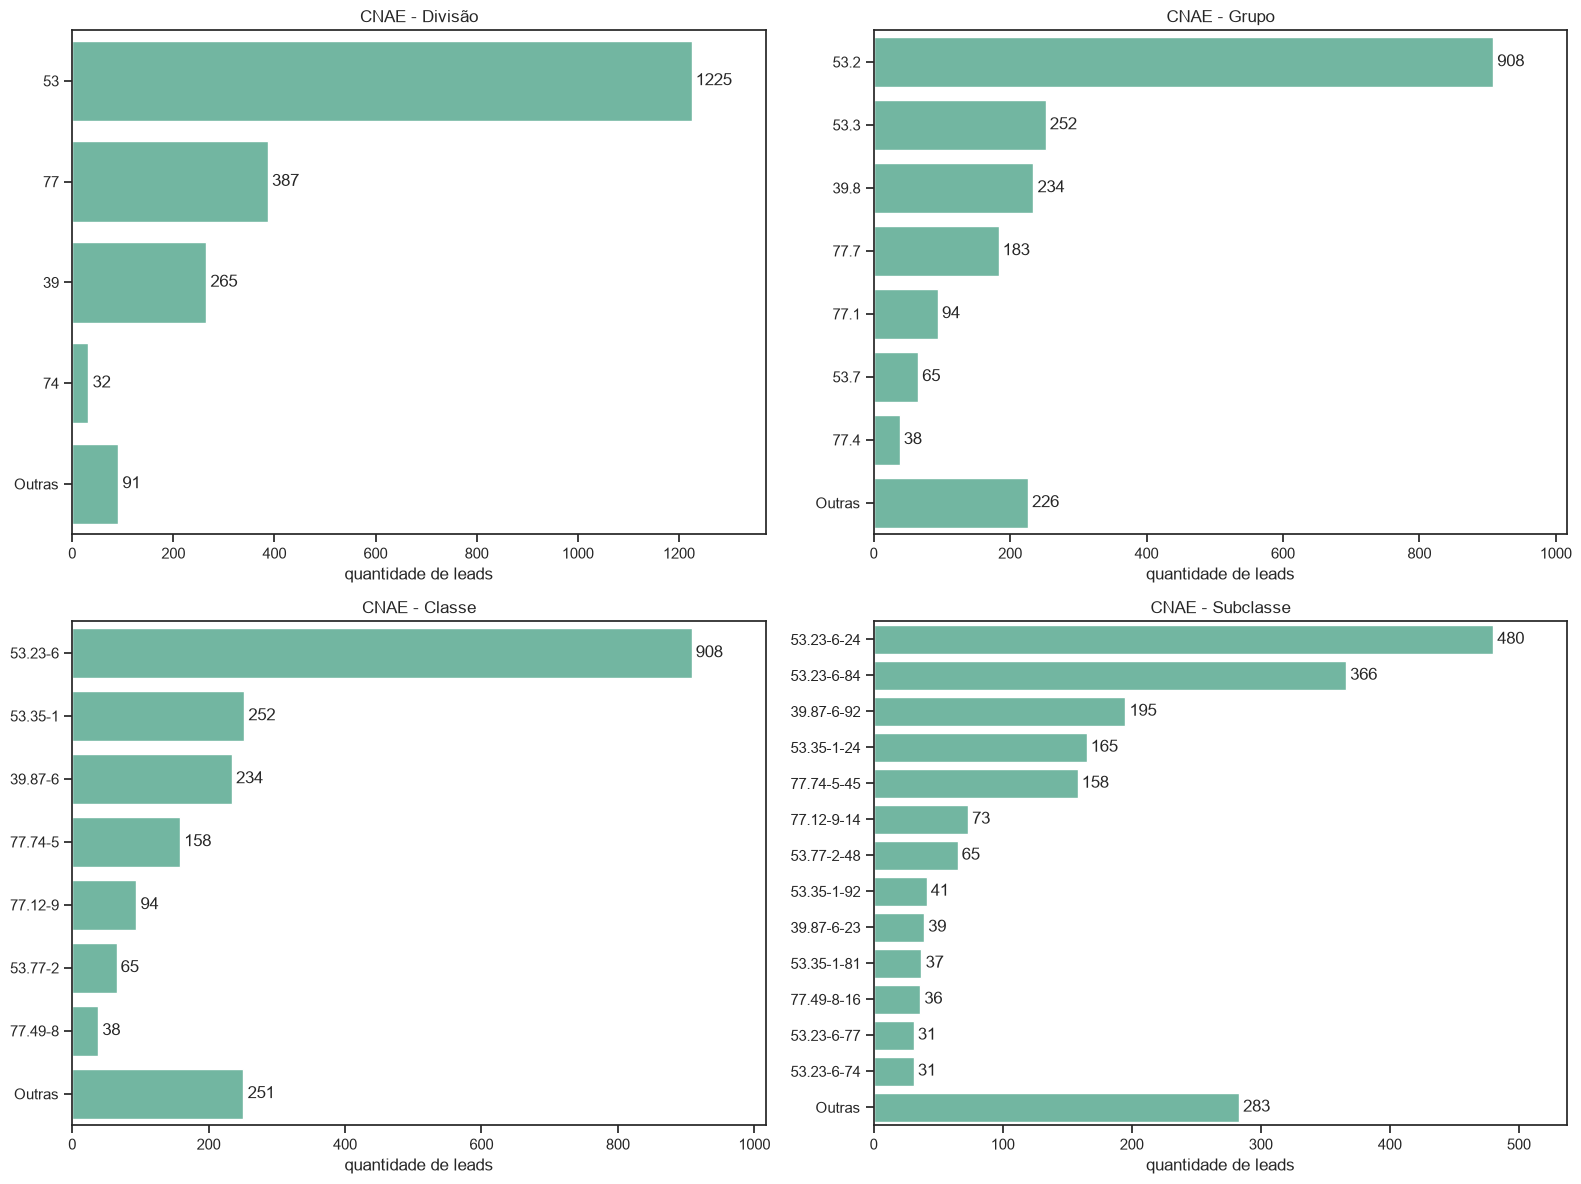

In [27]:
# hierarquia do CNAE no estilo do dataset:
# AA -> divisão | AA.B -> grupo | AA.BC-C -> classe | AA.BC-C-DD -> subclasse
leads['cnae_divisao'] = leads['cnae_codigo'].str[:2]
leads['cnae_grupo'] = leads['cnae_codigo'].str[:4]
leads['cnae_classe'] = leads['cnae_codigo'].str[:7]
leads['cnae_subclasse'] = leads['cnae_codigo']

print(f'exemplos de alguns códigos: {sorted(leads.cnae_codigo)[:5]}')

# quantas categorias existem em cada nível, e quantas têm pelo menos 30 leads
niveis = ['cnae_divisao', 'cnae_grupo', 'cnae_classe', 'cnae_subclasse']
titulos = ['Divisão', 'Grupo', 'Classe', 'Subclasse']
display(pd.DataFrame({
    'categorias': [leads[n].nunique() for n in niveis],
    'categorias com >= 30 leads': [(leads[n].value_counts() >= 30).sum() for n in niveis],
    'leads nessas categorias': [leads[n].map(leads[n].value_counts()).ge(30).sum() for n in niveis],
}, index=niveis))

axes = plot.figure(figsize=(16, 12)).subplots(2, 2)
for ax, nivel, titulo in zip(axes.flat, niveis, titulos):
    agrupado = agrupa_raras(leads[nivel])  # categorias com menos de 30 leads viram 'Outras'
    ordem = [c for c in agrupado.value_counts().index if c != 'Outras'] + ['Outras']

    sb.countplot(y=agrupado, order=ordem, ax=ax)
    ax.bar_label(ax.containers[0], padding=3)
    ax.margins(x=0.12)
    ax.set_title(f'CNAE - {titulo}')
    ax.set_xlabel('quantidade de leads')
    ax.set_ylabel('')
plot.tight_layout()

A distribuição é muito concentrada: a divisão 53 reúne 1225 dos 2000 leads, e as divisões 53, 77 (387) e 39 (265) somam 1877. Apenas 4 das 27 divisões têm pelo menos 30 leads. No grupo e na classe, a categoria mais frequente (53.2 e 53.23-6) concentra 908 leads. Conforme descemos na hierarquia, os dados se fragmentam: só 13 das 107 subclasses têm pelo menos 30 leads, e a quantidade de leads agrupados em "Outras" cresce de 91 (divisão) para 283 (subclasse).

#### Atributos do Serasa


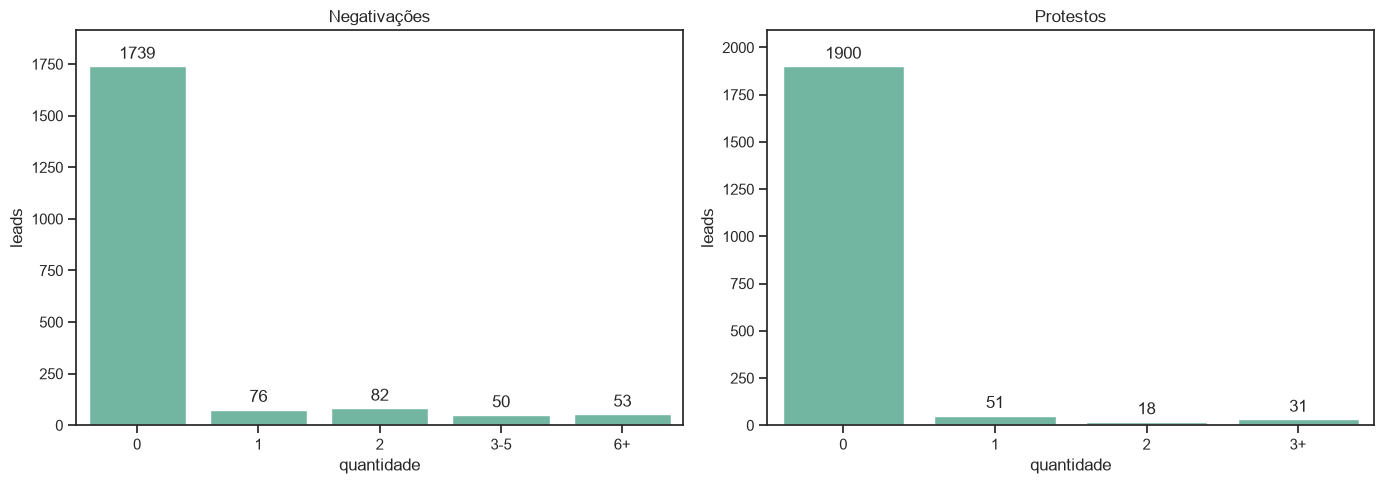

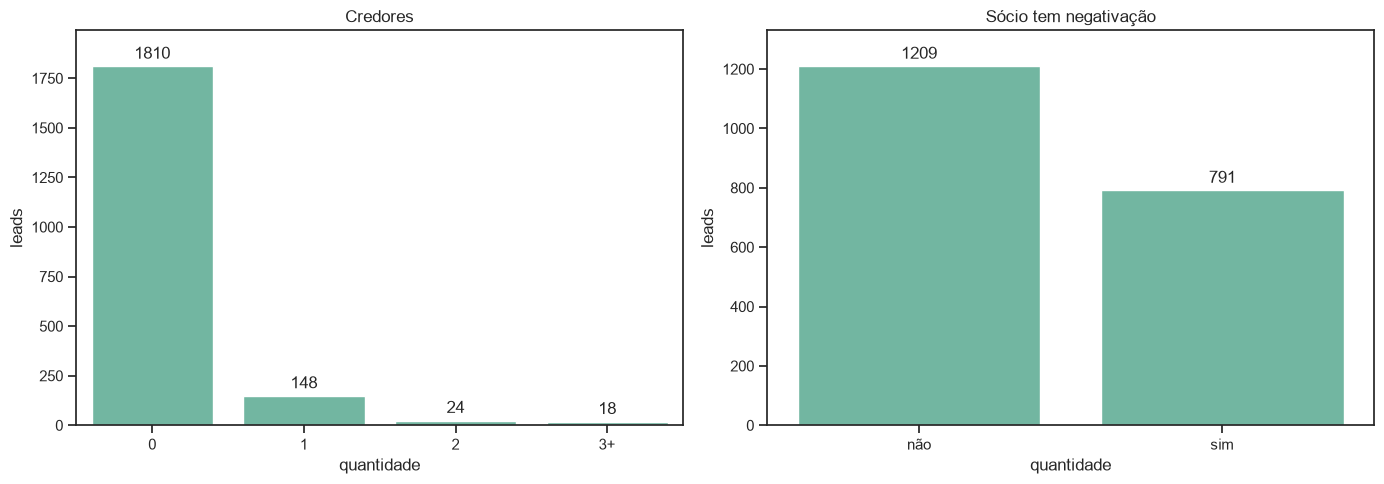

In [28]:
leads['qtd_credores'] = leads['serasa_credores'].str.split(', ').str.len().fillna(0).astype(int)

# a cauda é agrupada em poucas faixas - os valores altos são raros
leads['faixa_negativacoes'] = pd.cut(leads['serasa_contagem_negativacoes'], [-1, 0, 1, 2, 5, np.inf], labels=['0', '1', '2', '3-5', '6+'])
leads['faixa_protestos'] = pd.cut(leads['serasa_contagem_protestos'], [-1, 0, 1, 2, np.inf], labels=['0', '1', '2', '3+'])
leads['faixa_credores'] = pd.cut(leads['qtd_credores'], [-1, 0, 1, 2, np.inf], labels=['0', '1', '2', '3+'])
leads['socio_negativado'] = leads['serasa_socio_tem_negativacao'].map({0: 'não', 1: 'sim'})

def plota_dois(colunas, titulos):
    axes = plot.figure(figsize=(14, 5)).subplots(1, 2)
    for ax, coluna, titulo in zip(axes, colunas, titulos):
        sb.countplot(data=leads, x=coluna, ax=ax)
        ax.bar_label(ax.containers[0], padding=3)
        ax.margins(y=0.1)
        ax.set_title(titulo)
        ax.set_xlabel('quantidade')
        ax.set_ylabel('leads')
    plot.tight_layout()

plota_dois(['faixa_negativacoes', 'faixa_protestos'], ['Negativações', 'Protestos'])
plota_dois(['faixa_credores', 'socio_negativado'], ['Credores', 'Sócio tem negativação'])


Em todos eles o padrão é o mesmo: a grande maioria dos leads não tem nada registrado, e poucos concentram os valores altos. Isso significa que, sozinhas, essas variáveis têm pouca variabilidade e só distinguem um grupo pequeno de leads. Se houver impacto no churn, ele vem provavelmente de o lead estar ou não nesse grupo, e menos da magnitude. Além disso, os poucos valores muito altos podem distorcer qualquer análise que trate a contagem como uma escala numérica.

### 2.2 Comportamento de pedidos

Agora analisamos a distribuição dos atributos da tabela de **pedidos**, que descrevem o comportamento de compra dos clientes.


#### Valor e quantidade de produtos por pedido


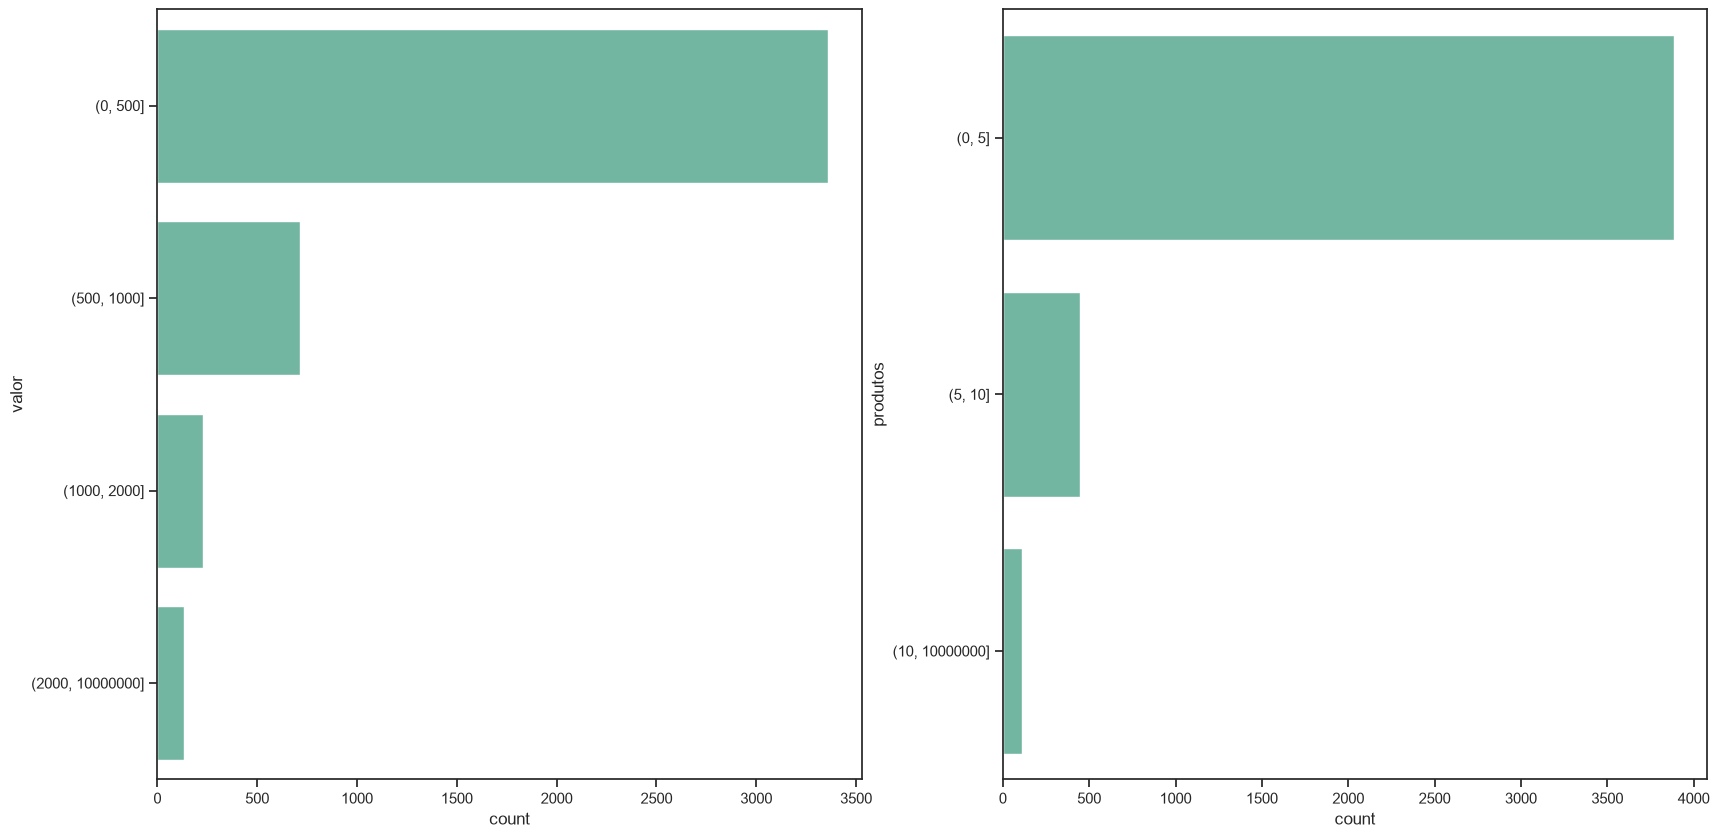

In [29]:
plot_ranged_countplot1x2(pedidos, ('valor', 'produtos'))

Isso nos deu um bom insight para o comportamento geral dos clientes registrados: os clientes da Praso tendem a comprar muitos produtos relativamente baratos e compram em baixa quantidade:

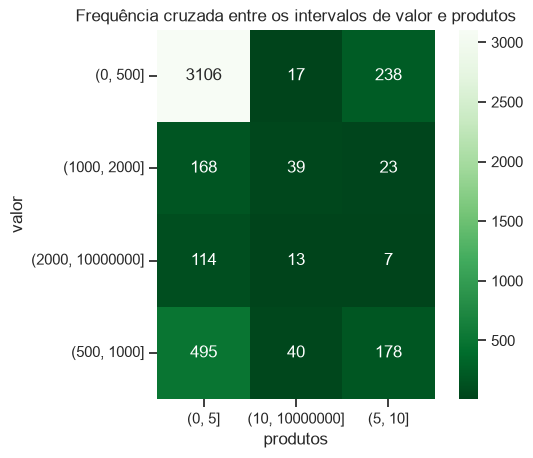

In [30]:
plot.title('Frequência cruzada entre os intervalos de valor e produtos')
_ = sb.heatmap(pd.crosstab(pedidos.valor, pedidos.produtos), annot=True, fmt='', square=True, cmap='Greens_r')


Nós tínhamos a impressão de que o valor de cada pedido estaria no intervalo mais baixo, mas que haveria uma quantidade maior de produtos comprados, seguindo o princípio da [curva ABC de produtos](https://www.cbsistemas.com.br/curva-abc-de-produtos-o-que-e-e-por-que-ela-e-tao-importante/), o qual nos foi introduzido durante a aula de conversa com um funcionário da Praso.

#### Data de entrega


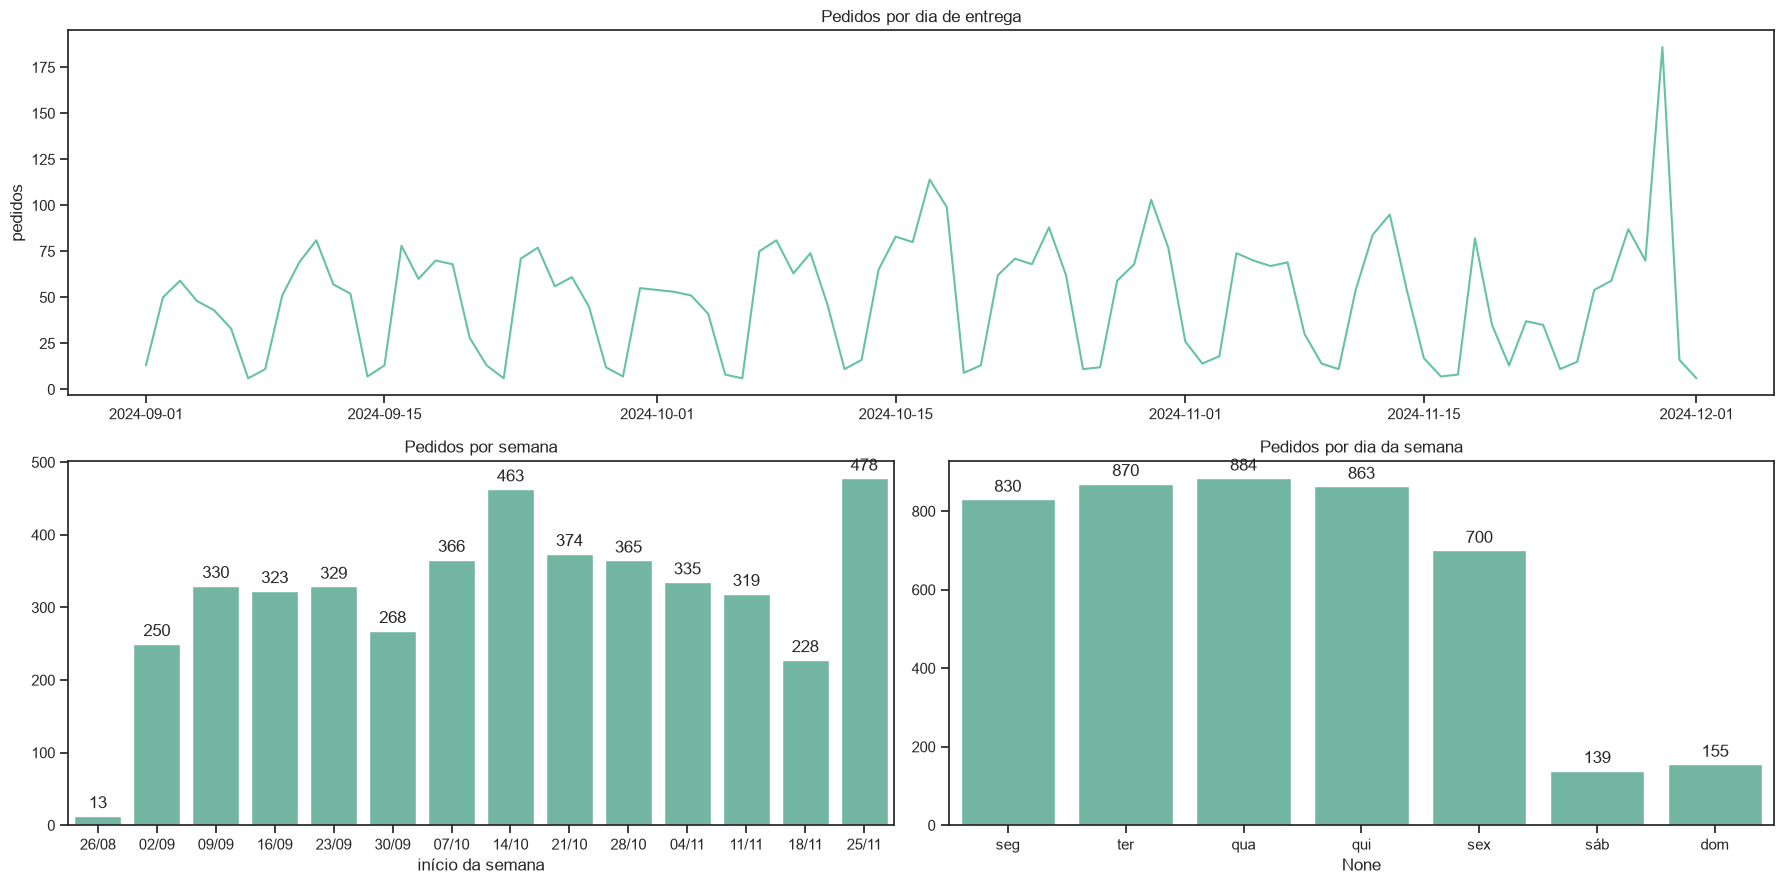

In [31]:
datas = pd.to_datetime(pedidos.data_entrega)

por_dia = datas.value_counts().sort_index().asfreq('D', fill_value=0)  # dias sem pedido contam como 0
por_semana = datas.dt.to_period('W').value_counts().sort_index()
por_dia_da_semana = datas.dt.dayofweek.value_counts().sort_index()
por_dia_da_semana.index = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']

fig, axes = plot.subplot_mosaic([['dia', 'dia'], ['semana', 'dia_semana']], figsize=(18, 9))

axes['dia'].plot(por_dia.index, por_dia.values)
axes['dia'].set_title('Pedidos por dia de entrega')
axes['dia'].set_ylabel('pedidos')

sb.barplot(x=por_semana.index.start_time.strftime('%d/%m'), y=por_semana.values, ax=axes['semana'])
axes['semana'].bar_label(axes['semana'].containers[0], padding=3)
axes['semana'].set_title('Pedidos por semana')
axes['semana'].set_xlabel('início da semana')

sb.barplot(x=por_dia_da_semana.index, y=por_dia_da_semana.values, ax=axes['dia_semana'])
axes['dia_semana'].bar_label(axes['dia_semana'].containers[0], padding=3)
axes['dia_semana'].set_title('Pedidos por dia da semana')

plot.tight_layout()


A entrega de pedidos tem uma sazonalidade semanal forte: o volume é alto de segunda a sexta e cai bastante no sábado e no domingo, o que é típico de um fornecedor que atende comércios. Fora esse padrão, o volume ao longo do trimestre é relativamente estável, sem tendência clara de crescimento ou queda. O maior pico do período está no último dia útil de novembro (29/11), que coincide com a Black Friday de 2024.

---


## 3. Análise bivariada


Vamos agora relacionar os atributos dos leads com o `churned`


### 3.1 Perfil dos leads


#### Teste qui-quadrado para as variáveis categóricas

Para saber se a diferença na taxa de churn entre as categorias de um atributo é grande o bastante para não ser mero acaso, usamos o teste qui-quadrado de independência. Quando o p-valor é menor que 0,05, consideramos que há relação entre o atributo e o churn. Categorias com menos de 30 leads são agrupadas em "Outras", porque amostras muito pequenas deixam a taxa de churn instável e atrapalham o teste.

A função abaixo mostra, para um atributo, o p-valor do teste e a quantidade de leads e a taxa de churn de cada categoria:

In [32]:
def analise_categorica(coluna, minimo=30):
    serie = leads[coluna].astype(str)
    contagem = serie.value_counts()
    serie = serie.where(serie.map(contagem) >= minimo, 'Outras')     # categorias com poucos leads viram 'Outras'

    # quantos leads e qual a taxa de churn de cada categoria
    tabela = leads.groupby(serie)['churned'].agg(leads='count', taxa_churn='mean')
    tabela['taxa_churn'] = (tabela['taxa_churn'] * 100).round(1)

    # qui-quadrado
    p = stats.chi2_contingency(pd.crosstab(serie, leads['churned']))[1]
    conclusao = 'há relação com o churn' if p < 0.05 else 'sem relação clara com o churn'
    print(f'{coluna}: p-valor = {p:.4f} -> {conclusao}')

    return tabela.sort_values('taxa_churn', ascending=False)

Vamos definir também algumas funções auxiliares, que serão usadas nas análises seguintes: uma que calcula a taxa de churn por categoria, uma que faz o teste qui-quadrado e calcula o V de Cramér (que mede a força da relação, de 0 a 1) e uma que desenha as barras de taxa de churn com o tamanho de cada grupo.

In [33]:
PALETA_CHURN = {0: '#6a00a8', 1: '#f89441'}
ROTULO_CHURN = {0: 'Retido', 1: 'Churned'}

def taxa_por_categoria(df, coluna, ordem=None):
    tabela = df.groupby(coluna, observed=True)['churned'].agg(clientes='count', churn='sum', taxa_churn='mean')
    return tabela.reindex(ordem).dropna(subset=['clientes']) if ordem is not None else tabela


def chi2_categorico(df, coluna):
    ct = pd.crosstab(df[coluna], df['churned'])
    ct = ct.loc[ct.sum(axis=1) > 0] # categorias sem nenhum cliente zerariam a frequência esperada
    chi2, p, _, esperado = stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramer_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    return p, cramer_v, esperado.min()


def barras_taxa_churn(tabela, ax, titulo, referencia=None, rotacao=0):
    # barras com a taxa de churn por categoria e o n de cada uma em cima
    tabela = tabela.copy()
    tabela.index = tabela.index.astype(str)
    ax.bar(tabela.index, tabela['taxa_churn'], color=PALETA_CHURN[1])
    for i, (n, taxa) in enumerate(zip(tabela['clientes'], tabela['taxa_churn'])):
        ax.text(i, taxa + 0.01, f'{taxa:.0%}\nn={int(n)}', ha='center', va='bottom', fontsize=9)
    if referencia is not None:
        ax.axhline(referencia, color='gray', linestyle='--', label=f'média geral ({referencia:.0%})')
        ax.legend(loc='upper right')
    ax.set_ylim(0, min(1.15, tabela['taxa_churn'].max() + 0.2))
    ax.set_title(titulo)
    ax.set_ylabel('taxa de churn')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=rotacao)

#### Fonte e segmento do cliente


<Axes: xlabel='count', ylabel='segmento_cliente'>

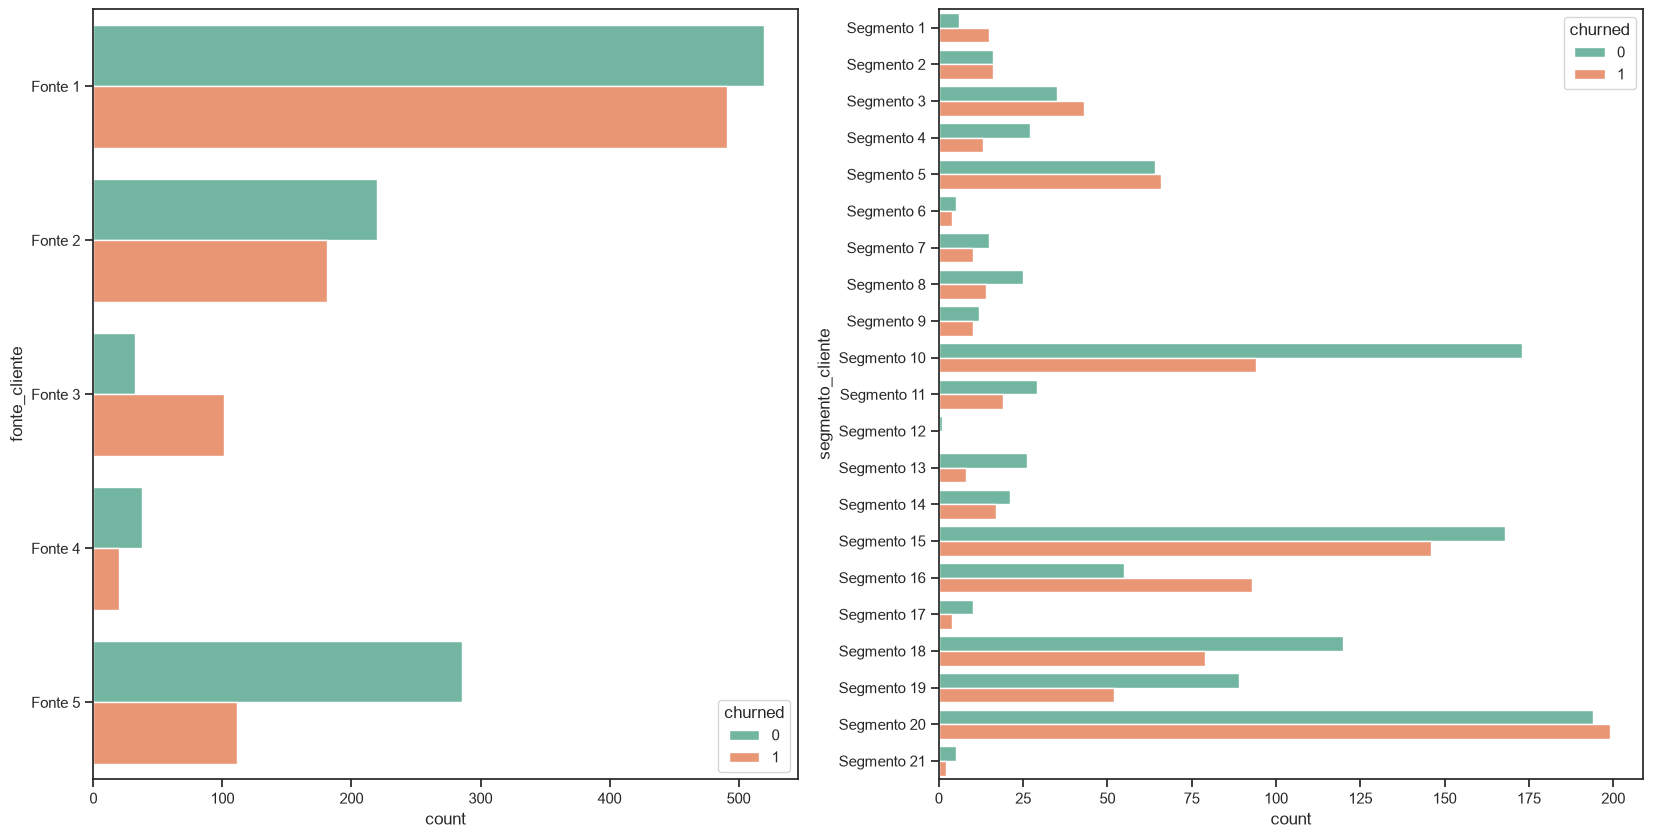

In [34]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)
sb.countplot(data=leads, hue='churned', y='fonte_cliente', order=fontes, ax=ax1)
sb.countplot(data=leads, hue='churned', y='segmento_cliente', order=segmentos, ax=ax2)

Para confirmar a relação que vemos no gráfico, aplicamos o teste qui-quadrado:

In [35]:
display(analise_categorica('fonte_cliente'))
display(analise_categorica('segmento_cliente'))

fonte_cliente: p-valor = 0.0000 -> há relação com o churn


,leads,taxa_churn
fonte_cliente,,
Fonte 3,133,75.9
Fonte 1,1011,48.6
Fonte 2,401,45.1
Fonte 4,58,34.5
Fonte 5,397,28.0


segmento_cliente: p-valor = 0.0000 -> há relação com o churn


,leads,taxa_churn
segmento_cliente,,
Segmento 16,148,62.8
Segmento 3,78,55.1
Segmento 5,130,50.8
Segmento 20,393,50.6
Segmento 2,32,50.0
Segmento 15,314,46.5
Outras,99,45.5
Segmento 14,38,44.7
Segmento 18,199,39.7


Fonte e segmento são rótulos anonimizados; o número é só um identificador, sem ordem. O teste qui-quadrado indica relação com o churn nos dois atributos (p ≈ 0,0000).

Fonte: a Fonte 3 (133 clientes) tem churn de 75,9%, muito acima das demais, e a Fonte 5 (397) tem o menor, 28,0%. As Fontes 1 (1011) e 2 (401) ficam em 48,6% e 45,1%, e a Fonte 4 (58) em 34,5%.
Segmento: o Segmento 16 (148 clientes) tem o maior churn entre os que têm amostra razoável, 62,8%, e o 13 (34) tem o menor, 23,5%. No gráfico, os Segmentos 10, 18 e 19 têm mais retidos que churned, e os Segmentos 16 e 3 têm o inverso.
Os Segmentos 1, 6, 7, 9, 12, 17 e 21 têm menos de 30 clientes cada (de 1 a 25). Suas taxas não são confiáveis e foram agrupadas em "Outras" na análise.

#### Natureza jurídica e idade do CNPJ

In [47]:
display(analise_categorica('natureza_juridica'))
display(analise_categorica('idade_cnpj'))

natureza_juridica: p-valor = 0.0042 -> há relação com o churn


,leads,taxa_churn
natureza_juridica,,
213-5 - Empresário (Individual),1390,47.4
206-2 - Sociedade Empresária Limitada,607,40.4
Outras,3,0.0


idade_cnpj: p-valor = 0.8056 -> sem relação clara com o churn


,leads,taxa_churn
idade_cnpj,,
"(3000, 4000]",156,52.6
"(100, 150]",87,51.7
"(50, 100]",100,50.0
"(2400, 3000]",126,49.2
"(150, 250]",109,47.7
"(1600, 2000]",131,47.3
"(1150, 1300]",73,46.6
"(900, 1150]",133,46.6
"(2000, 2400]",95,45.3


A natureza jurídica tem relação com o churn (p ≈ 0,004): os empresários individuais (`213-5`) têm taxa de churn de 47,4%, contra 40,4% das sociedades empresárias limitadas (`206-2`). As outras duas categorias somam apenas 3 leads, então não dá para avaliá-las isoladamente, o que reforça a ideia de agrupá-las com as categorias majoritárias de características parecidas.

A idade do CNPJ, por outro lado, não mostra relação clara com o churn (p ≈ 0,81): as taxas variam de 37,7% a 52,6% entre as faixas, sem um padrão que cresça ou diminua com a idade. Levantamos a hipótese de que empresas mais jovens seriam mais frágeis e dariam mais churn, mas os dados não sustentam isso.

#### Negativações e credores no Serasa

Text(0.5, 1.0, 'Contagem de amostras em relação ao churn (para referência)')

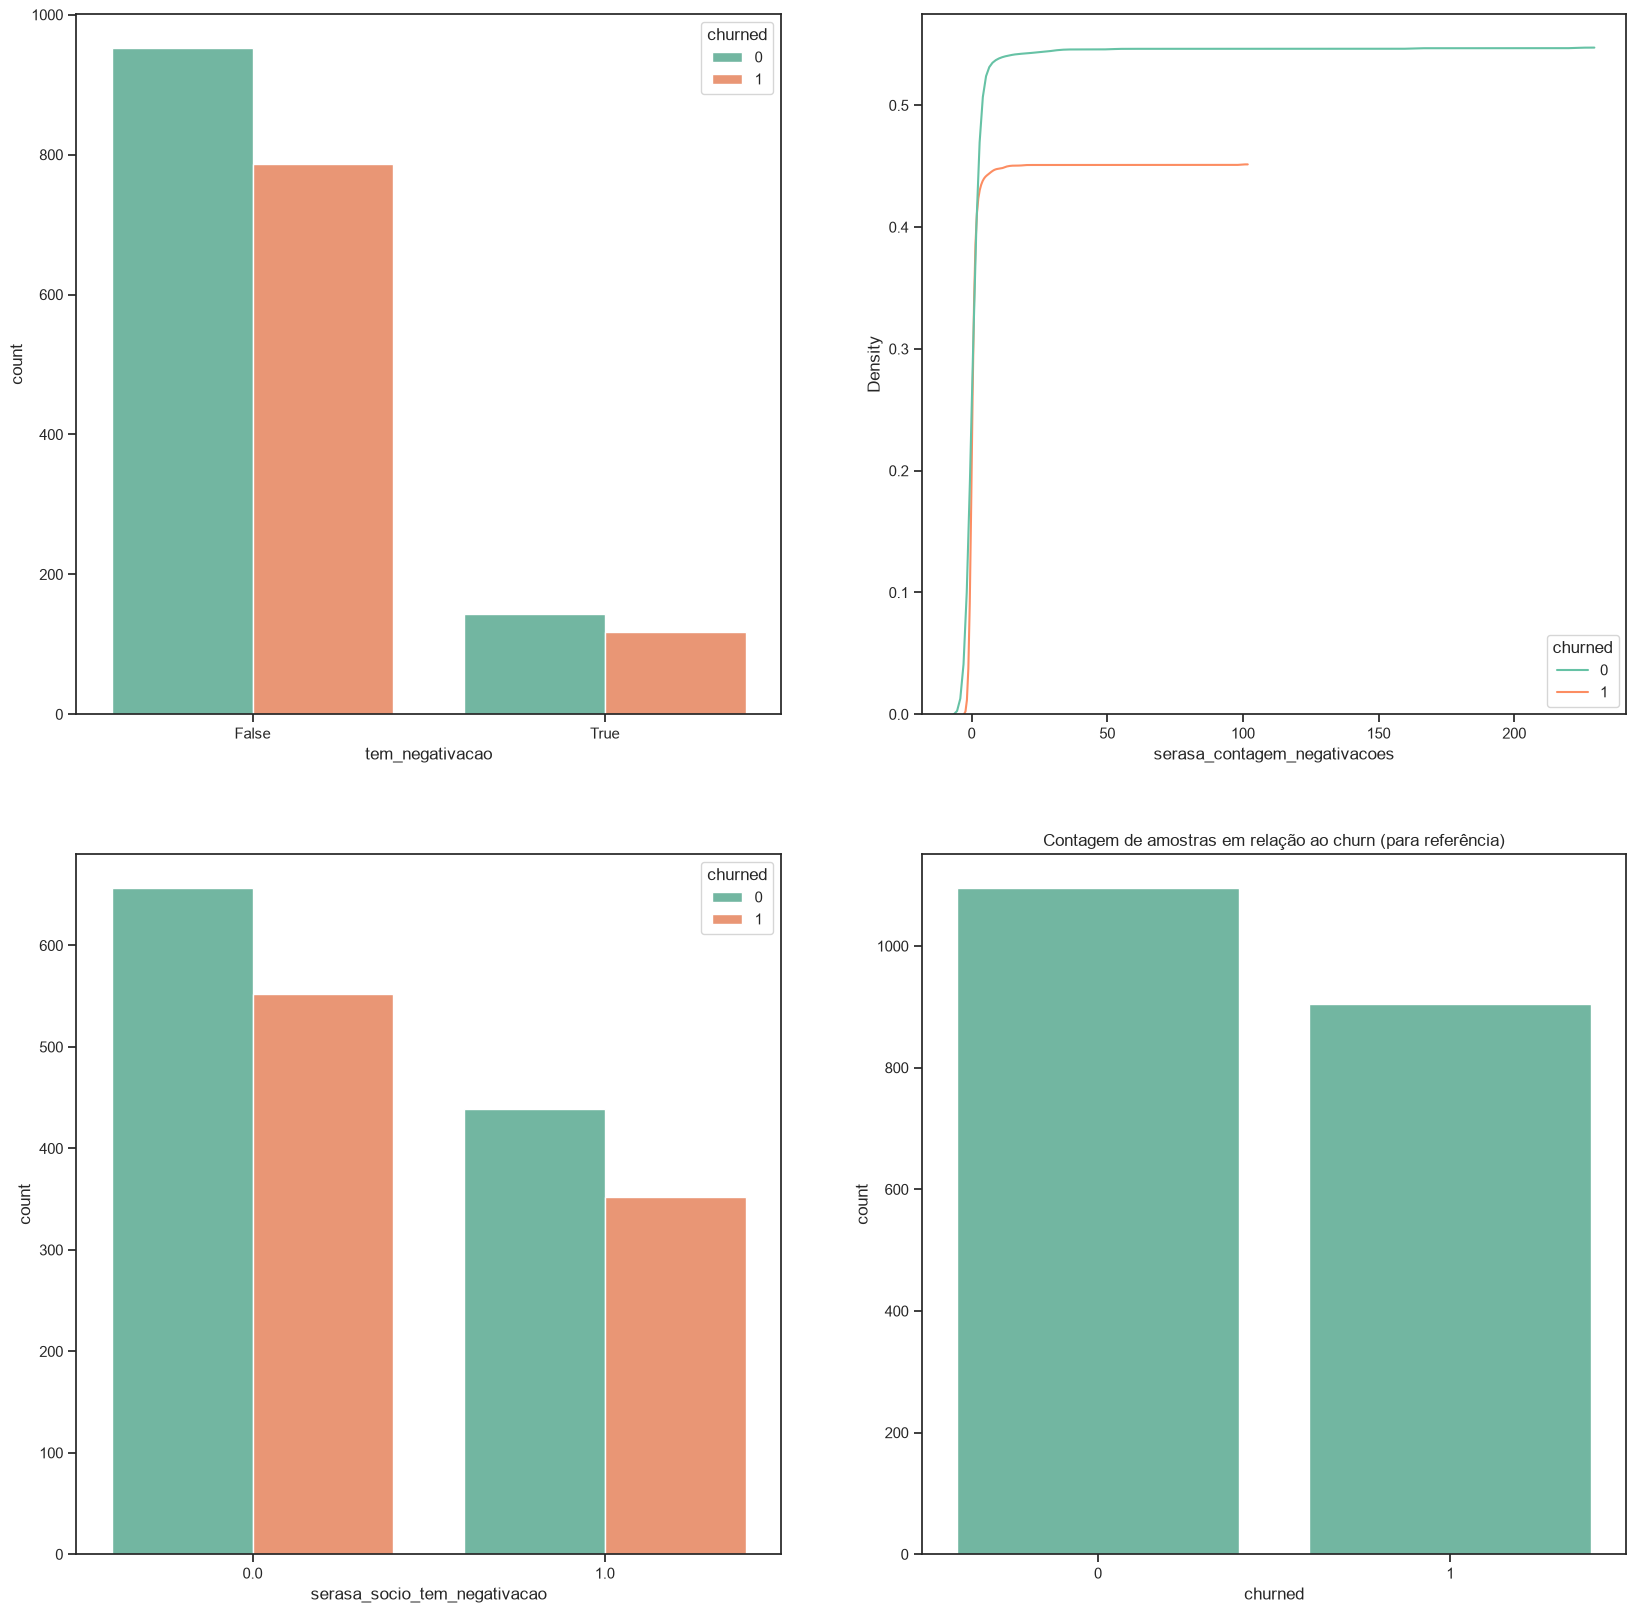

In [36]:
(ax1, ax2), (ax3, ax4) = plot.figure(figsize=(20, 20)).subplots(2, 2)

leads['tem_negativacao'] = leads.serasa_contagem_negativacoes > 0

sb.countplot(data=leads, x='tem_negativacao', hue='churned', ax=ax1)
sb.kdeplot(data=leads, x='serasa_contagem_negativacoes', hue='churned', ax=ax2, cumulative=True)

sb.countplot(data=leads, x='serasa_socio_tem_negativacao', hue='churned', ax=ax3)
sb.countplot(data=leads, x='churned', ax=ax4)
ax4.set_title('Contagem de amostras em relação ao churn (para referência)')

no geral, as duas variáveis seguem o mesmo padrão do gráfico de referência: a maioria dos clientes não dá churn, com ou sem negativação. Tanto em tem_negativacao quanto em serasa_socio_tem_negativacao, a proporção entre quem dá e quem não dá churn quase não muda entre as categorias,ou seja, ter negativação (própria ou do sócio) não parece fazer muita diferença pro churn

**Quantidade de credores:**

<Axes: xlabel='faixa_credores', ylabel='count'>

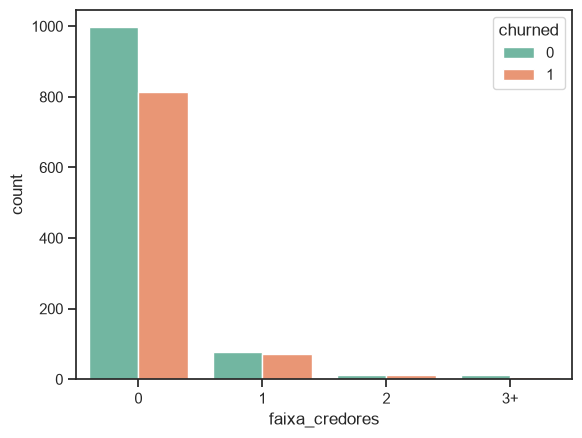

In [37]:
sb.countplot(data=leads, x='faixa_credores', hue='churned')

a taxa de churn não muda muito com a quantidade de credores (fica entre 39% e 54%), e os grupos com 2 ou 3+ credores têm poucas amostras (24 e 18 leads), então não dá pra confiar muito numa tendência aí.

**Tipos de credor:**

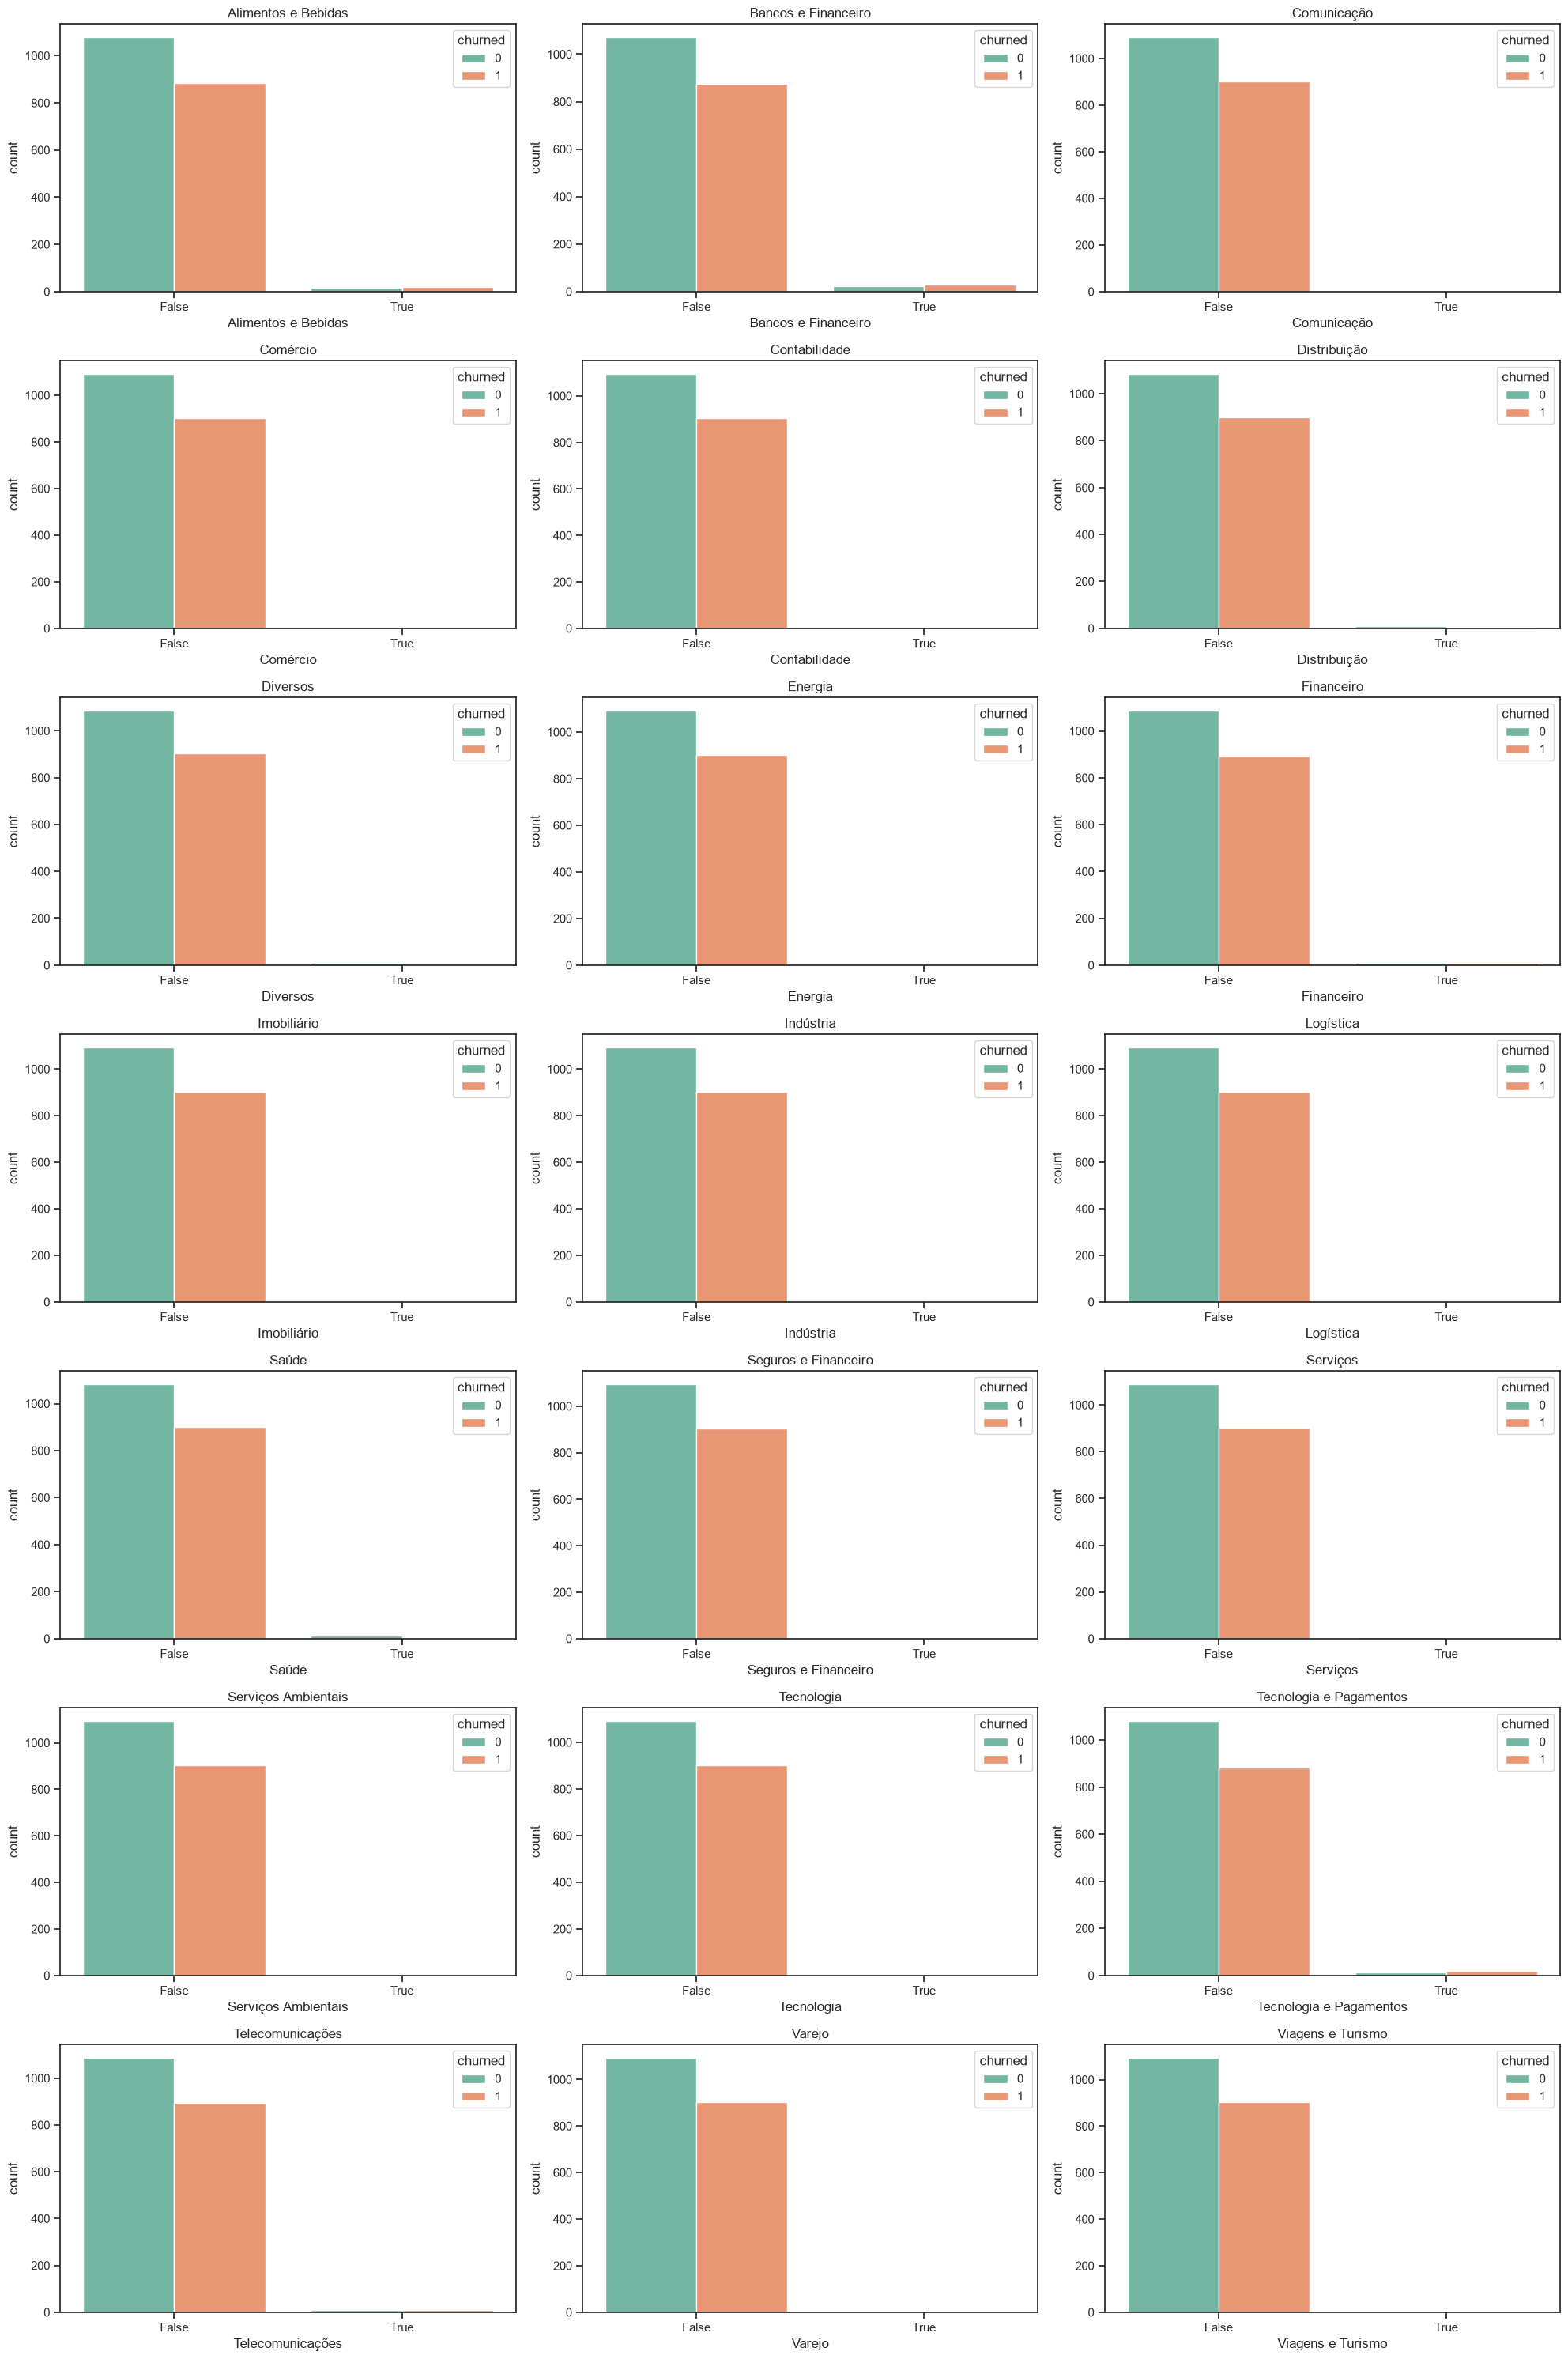

In [38]:
credores: set[str] = set()
for credor in leads.serasa_credores.dropna().unique():
    credores.update(credor.split(', '))

axes = plot.figure(figsize=(20, 30)).subplots(7, 3)
for i, tipo_credor in enumerate(sorted(credores)):
    ax = axes[i // 3][i % 3]
    leads[tipo_credor] = leads.serasa_credores.apply(lambda obj: tipo_credor in obj.split(', ') if isinstance(obj, str) else False)
    sb.countplot(data=leads, x=tipo_credor, hue='churned', ax=ax)
    ax.set_title(tipo_credor)
plot.tight_layout()

a maioria dos tipos de credor tem pouquíssimas amostras (vários com menos de 10 leads, alguns com só 1), então a taxa de churn de cada tipo isolado não é confiável. chegamos a pensar em separar `Tecnologia e Pagamentos` em duas categorias, mas como já são só 34 leads nessa categoria, dividir ia deixar as duas partes ainda menores e a gente ia perder a relação entre elas. além disso, olhando os tipos com mais amostra, a taxa de churn fica numa faixa parecida (perto de 50%), sem nenhum se destacar muito, então não parece valer a pena detalhar mais os tipos de credor.

**Protestos:**

In [ ]:
leads['tem_protesto'] = leads.serasa_contagem_protestos > 0

sb.countplot(data=leads, x='tem_protesto', hue='churned')

# proporção de churn dentro de cada grupo
pd.crosstab(leads.tem_protesto, leads.churned, normalize='index')

Os leads com protesto são uma minoria pequena, e entre eles a taxa de churn é de 38%, um pouco menor que a dos leads sem protesto (cerca de 46%). O sentido é o contrário do que supúnhamos (situação financeira pior levaria a mais churn), mas a diferença é pequena e vem de um grupo pequeno, então não há evidência forte de relação.

**Quem tem credor também tem negativação?**

In [48]:
leads['tem_credor'] = leads['serasa_credores'].notna()
leads['tem_negativacao'] = leads['serasa_contagem_negativacoes'] > 0

print('% com negativação, entre quem tem e quem não tem credor:')
print((leads.groupby('tem_credor')['tem_negativacao'].mean() * 100).round(1).to_string())

print('\nchurn entre os leads com negativação, com e sem credor:')
taxa_por_categoria(leads[leads['tem_negativacao']], 'tem_credor')

% com negativação, entre quem tem e quem não tem credor:
tem_credor
False      3.9
True     100.0

churn entre os leads com negativação, com e sem credor:


,clientes,churn,taxa_churn
tem_credor,,,
False,71,27,0.380282
True,190,91,0.478947


Todos os leads que têm credor também têm negativação (100%), enquanto só 3,9% dos leads sem credor têm negativação. Ou seja, ter credor é um caso particular de ter negativação. Entre os leads com negativação, os que têm credor têm taxa de churn um pouco maior (47,9%, contra 38,0% dos negativados sem credor), uma diferença modesta que não muda o quadro geral do Serasa.

#### CNAE

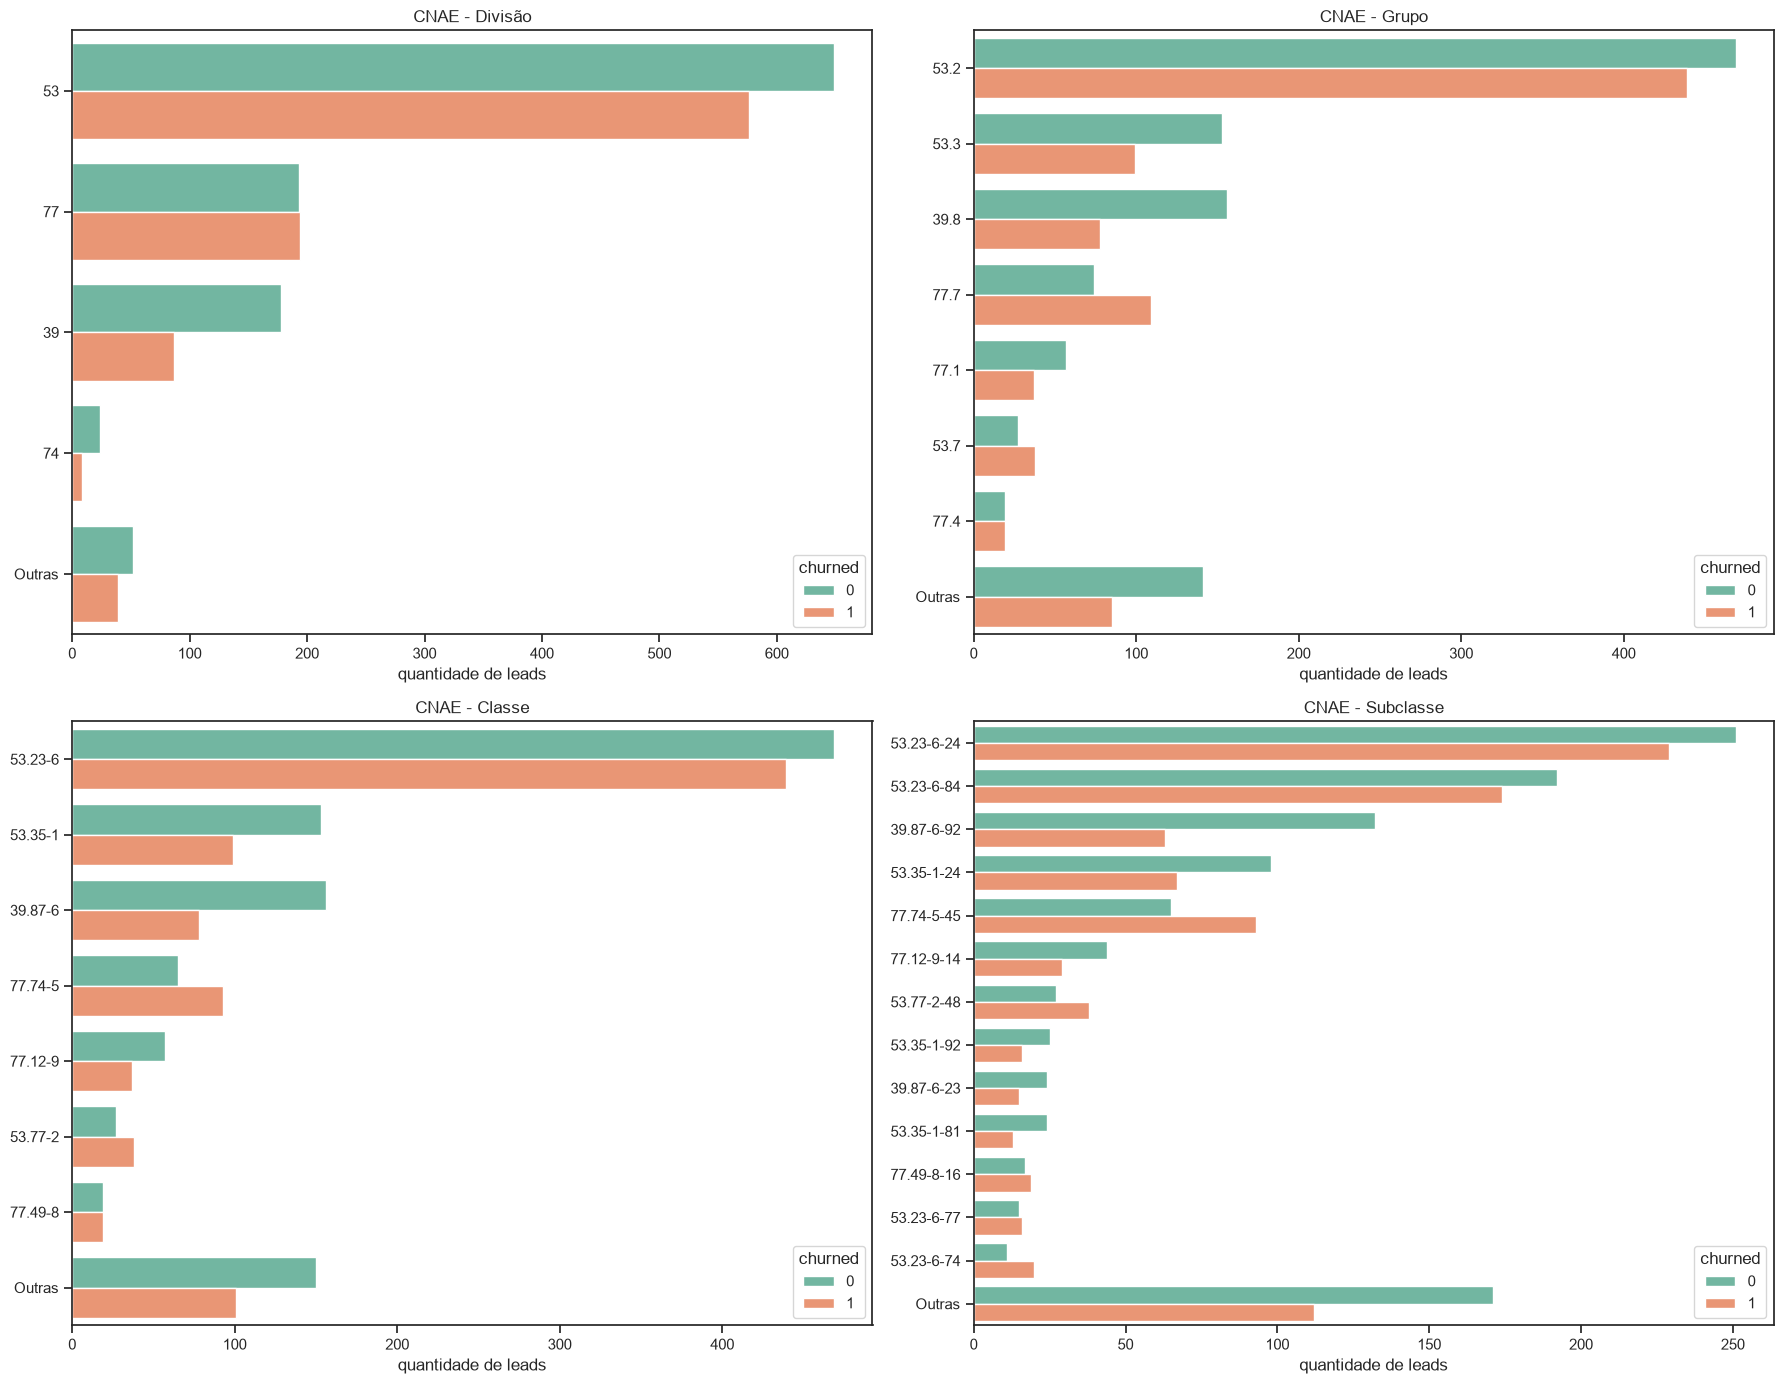

In [39]:
# niveis e titulos já foram definidos na análise univariada do CNAE (seção 2.1)
axes = plot.figure(figsize=(18, 14)).subplots(2, 2)
for ax, nivel, titulo in zip(axes.flat, niveis, titulos):
    agrupado = agrupa_raras(leads[nivel])  # categorias com menos de 30 leads viram 'Outras'
    ordem = [c for c in agrupado.value_counts().index if c != 'Outras'] + ['Outras']

    sb.countplot(data=leads, y=agrupado, hue=leads.churned, order=ordem, ax=ax)
    ax.set_title(f'CNAE - {titulo}')
    ax.set_xlabel('quantidade de leads')
    ax.set_ylabel('')
plot.tight_layout()

a divisão 39 chama atenção por ter uma taxa de churn visivelmente mais baixa que as outras, e esse padrão se repete nos grupos, classes e subclasses que vêm dela. Só que, conforme a gente desce na hierarquia, sobra cada vez menos lead por categoria,a maioria vira "Outras" por ter poucos dados, igual já tínhamos visto na univariada. Como o padrão de churn por divisão já aparece nos níveis mais fundos, não parece valer a pena olhar além da divisão.

#### CNAE × Segmento

<Axes: title={'center': 'Distribuição das divisões de CNAE dentro de cada segmento'}, xlabel='cnae_divisao', ylabel='segmento_cliente'>

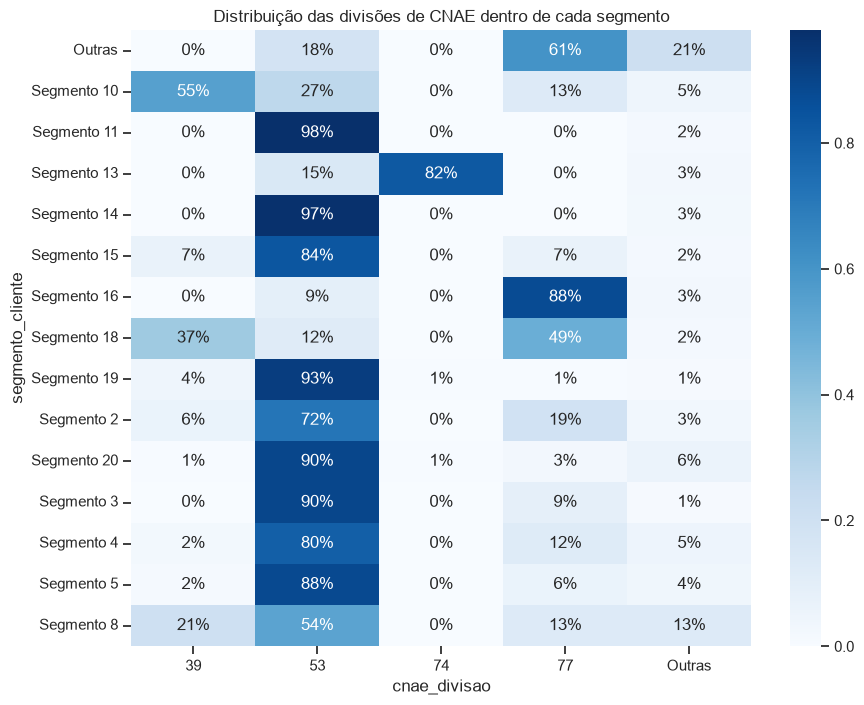

In [40]:
seg = agrupa_raras(leads['segmento_cliente'])
cnae = agrupa_raras(leads['cnae_divisao'])

proporcao = pd.crosstab(seg, cnae, normalize='index')

plot.figure(figsize=(10, 8))
plot.title('Distribuição das divisões de CNAE dentro de cada segmento')
sb.heatmap(proporcao, annot=True, fmt='.0%', cmap='Blues')

dá pra ver que o segmento praticamente determina a divisão do CNAE: a maioria dos segmentos está concentrada numa única divisão. o caminho contrário não é tão forte assim, uma mesma divisão aparece espalhada em vários segmentos. isso sugere que `segmento_cliente` carrega mais informação que `cnae_divisao` sozinho. conversamos com o professor sobre essa correlação forte entre os dois atributos, e ele sugeriu que a gente descarte o CNAE também, já que o segmento cobre boa parte dessa informação.

#### Região e município

<Axes: xlabel='regiao', ylabel='count'>

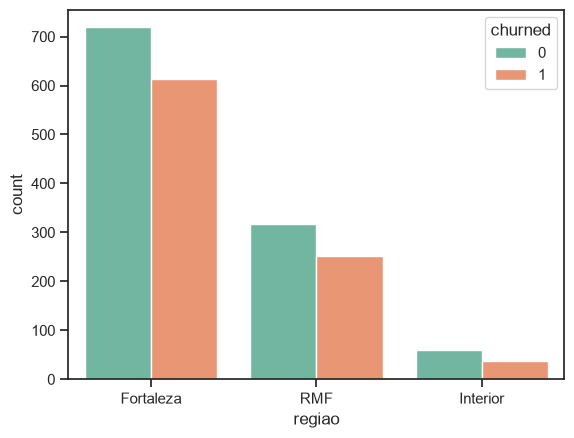

In [41]:
sb.countplot(data=leads, x='regiao', hue='churned', order=['Fortaleza', 'RMF', 'Interior'])

município sozinho é muito específico pra olhar direto, são 31 valores, boa parte com poucas dezenas de leads, então faz mais sentido comparar pela região (Fortaleza / RMF / interior), que já é uma visão mais estável. a taxa de churn fica bem parecida nas três

#### Presença no iFood


<Axes: title={'center': 'Tabela de frequência entre tem_ifood e churn'}, xlabel='churned', ylabel='tem_ifood'>

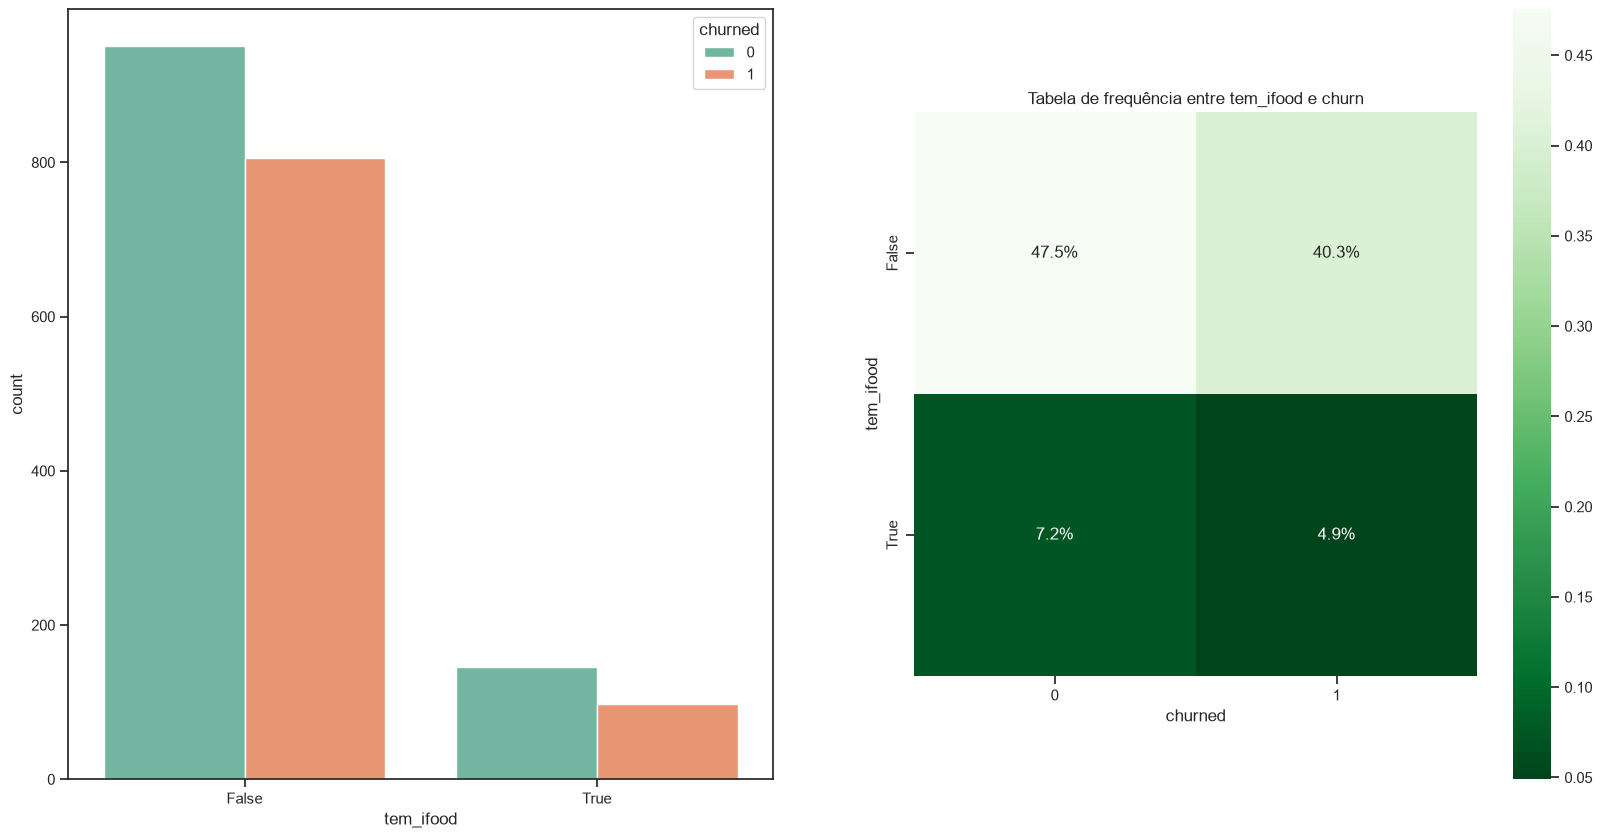

In [42]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

leads['tem_ifood'] = leads.ifood_faixa_preco.notna()

sb.countplot(data=leads, x='tem_ifood', hue='churned', ax=ax1)

ax2.set_title('Tabela de frequência entre tem_ifood e churn')
sb.heatmap(pd.crosstab(leads.tem_ifood, leads.churned, normalize=True), annot=True, fmt='.1%', square=True, cmap='Greens_r', ax=ax2)

de modo geral, quem tem ifood tem uma chance um pouco maior de não dar churn.

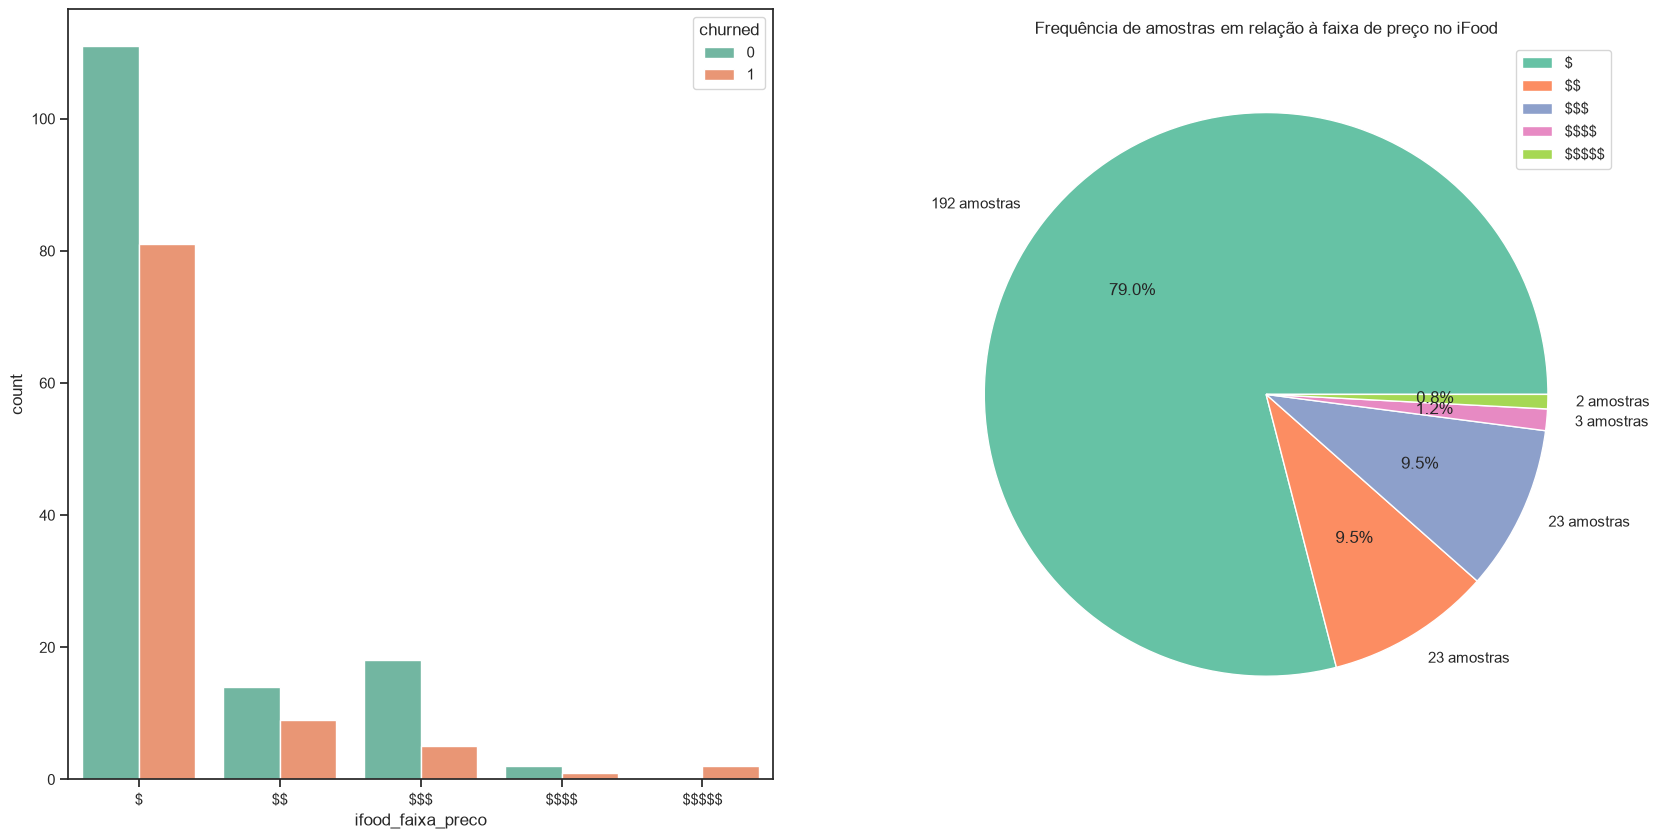

In [43]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

# Escapando os caracteres '$' para evitar erros com o matplotlib
leads.ifood_faixa_preco = leads.ifood_faixa_preco.apply(lambda x: x.replace('$', '\\$') if pd.notna(x) else x)
faixas = sorted(leads.ifood_faixa_preco.dropna().unique())

sb.countplot(data=leads, x='ifood_faixa_preco', hue='churned', order=faixas, ax=ax1)

contagem_de_faixas = leads.ifood_faixa_preco.value_counts()

ax2.set_title('Frequência de amostras em relação à faixa de preço no iFood')
ax2.pie(contagem_de_faixas, labels=[f'{contagem} amostras' for contagem in contagem_de_faixas], autopct='%.1f%%')
ax2.legend(faixas)

no geral dá pra ver que os pedidos no iFood são baratos: a faixa $ sozinha já é quase 80% da amostra e as faixas mais caras têm praticamente nada, só 2 e 3 clientes. Só que essa variável já tem poucas amostras de cara e dividindo ainda em 5 faixas de preço isso fica bem esparso, então não dá pra confiar muito no padrão da faixa em si. Faz mais sentido a gente tratar de maneira geral, sem se preocupar com a faixa de preço específica.

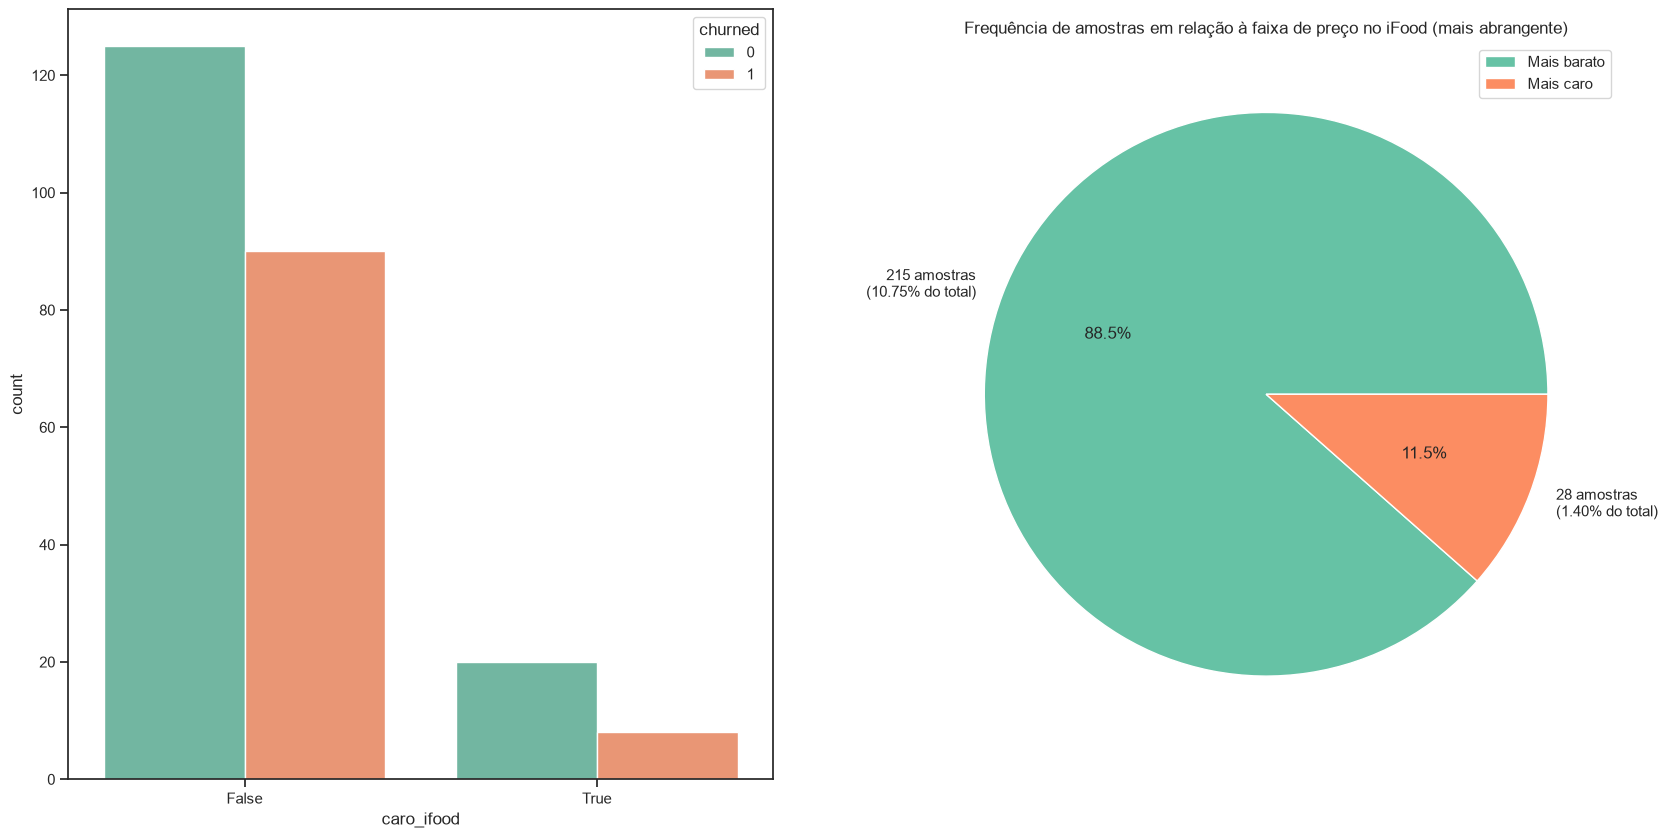

In [44]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

leads['caro_ifood'] = leads.ifood_faixa_preco.apply(lambda x: x if pd.isna(x) else len(x) >= len('\\$' * 3))
sb.countplot(data=leads, x='caro_ifood', hue='churned', ax=ax1)

contagem_mais_abrangente = leads.caro_ifood.value_counts()

ax2.set_title('Frequência de amostras em relação à faixa de preço no iFood (mais abrangente)')
ax2.pie(contagem_mais_abrangente, labels=[f'{contagem} amostras\n({100*contagem / leads.shape[0]:.2f}% do total)' for contagem in contagem_mais_abrangente], autopct='%.1f%%')
ax2.legend(['Mais barato', 'Mais caro'])

quem ta no ifood tem a mesma tendencia de dar menos churn, independente do preço. (a diferença eh menos gritante pro ifoodcaro=True pq tem menos amostras e algumas das categorias tem praticamente so amostra de um jeito ent enviesa) motivo pra gente descartar essa variavel

#### Google Maps


google_maps_avaliacao
(4.5, 5.0]    30
(3.0, 4.0]     7
(2.0, 3.0]     3
(1.0, 2.0]     3
(0.0, 1.0]     1
Name: count, dtype: int64

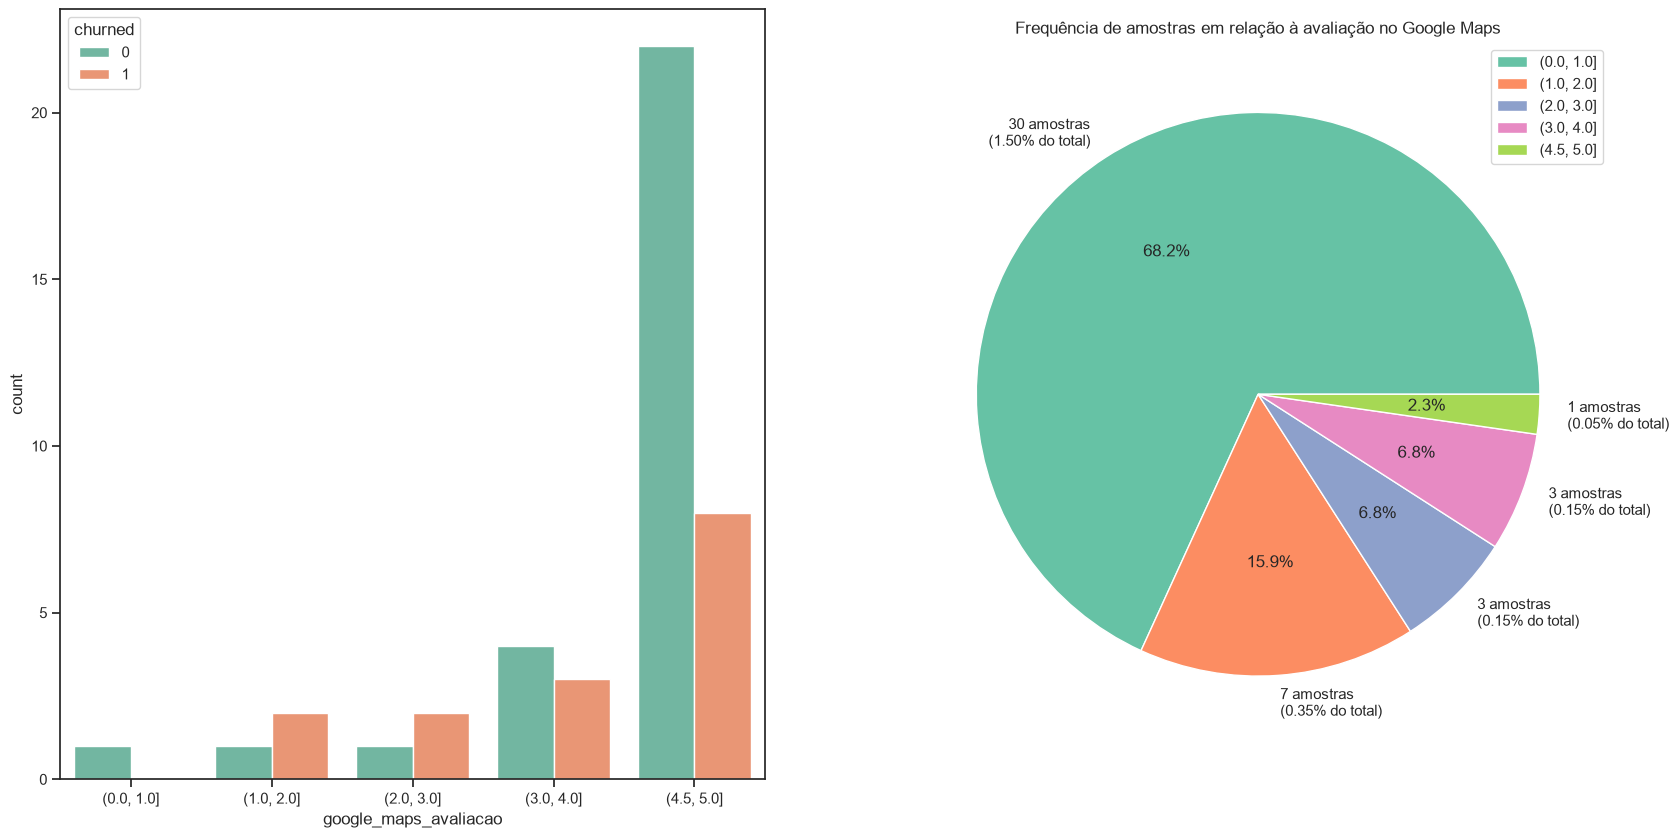

In [45]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

sb.countplot(data=leads, x='google_maps_avaliacao', hue='churned', order=sort_by_range(leads.google_maps_avaliacao.dropna().unique(), is_float=True), ax=ax1)

contagem_de_faixas = leads.google_maps_avaliacao.value_counts()

ax2.set_title('Frequência de amostras em relação à avaliação no Google Maps')
ax2.pie(contagem_de_faixas, labels=[f'{contagem} amostras\n({100*contagem / leads.shape[0]:.2f}% do total)' for contagem in contagem_de_faixas], autopct='%.1f%%')
ax2.legend(sort_by_range(leads.google_maps_avaliacao.dropna().unique(), is_float=True))

contagem_de_faixas

tem quase nada com avaliacao, pq nao tem quase nada com google maps. apesar de ter um padrão promissor, achamos melhor nesse caso desconsiderar pelo tamanho minúsculo de amostras com esse campo em comparação com o todo.


<Axes: title={'center': 'Tabela de frequência entre google_maps_tem_website e churn'}, xlabel='churned', ylabel='google_maps_tem_website'>

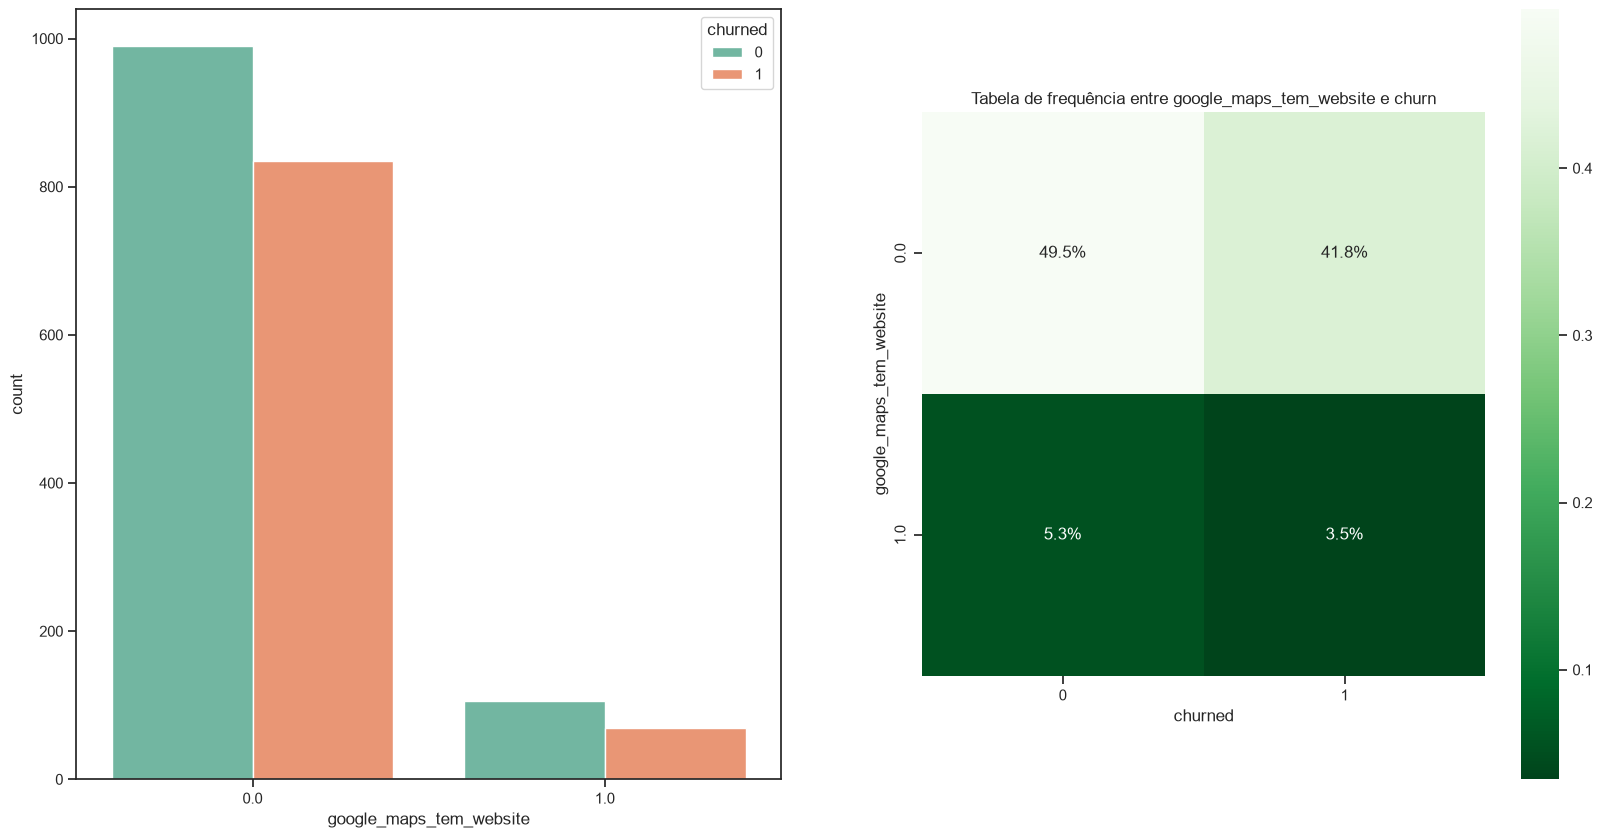

In [46]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

leads.google_maps_tem_website = leads.google_maps_tem_website.apply(lambda x: 0 if pd.isna(x) else x)

sb.countplot(data=leads, x='google_maps_tem_website', hue='churned', ax=ax1)

ax2.set_title('Tabela de frequência entre google_maps_tem_website e churn')
sb.heatmap(pd.crosstab(leads.google_maps_tem_website, leads.churned, normalize=True), annot=True, fmt='.1%', square=True, cmap='Greens_r', ax=ax2)

pode-se ver que no geral, podemos assumir que quem tem website tem chance ligeiramente menor de dar churn, se você comparar as porcentagens. isso é similar à questão do ifood

### 3.2 Comportamento de pedidos


Os pedidos mostram como cada cliente se comportou ao longo do trimestre. Como a tabela de pedidos tem várias linhas por cliente, primeiro resumimos o comportamento de cada um (quantos pedidos fez, há quanto tempo fez o último, qual o intervalo típico entre pedidos e qual faixa de valor e de produtos costuma comprar) e depois comparamos esses resumos com o churn.

Apenas 1000 dos 2000 leads têm pedidos na tabela, e só sobre eles o comportamento pode ser analisado. Os demais não têm pedidos no período, o que não quer dizer que nunca tenham pedido, já que a tabela cobre só 92 dias. Para eles, a ausência de pedidos é a própria informação.

Começamos convertendo a data de entrega para data. Note que a coluna é a data de entrega do pedido, e não a data em que ele foi feito. Vários pedidos no mesmo dia contam como um único dia de compra.

In [ ]:
# vários pedidos no mesmo dia contam como 1 dia
pedidos['data'] = pd.to_datetime(pedidos['data_entrega'])
print('de', pedidos['data'].min().date(), 'até', pedidos['data'].max().date())

Como `valor` e `produtos` são faixas, e não números, resumimos cada cliente pela **faixa mais frequente** entre seus pedidos (a moda). Quando há empate, ficamos com a faixa maior. Também guardamos a **maior faixa** que o cliente já atingiu. As funções abaixo calculam esses resumos e fazem a análise com o churn (vamos usá-las mais adiante):

In [ ]:
def faixas_por_cliente(coluna):
    # ordem natural das faixas, do menor para o maior intervalo 
    ordem = sort_by_range(pedidos[coluna].dropna().unique())
    tipo = pd.CategoricalDtype(ordem, ordered=True)

    ped = pedidos[['id_cliente', coluna]].dropna().copy()
    ped[coluna] = ped[coluna].astype(tipo)

    contagem = pd.crosstab(ped['id_cliente'], ped[coluna]).reindex(columns=ordem)
    # moda com empate -> faixa maior: inverte as colunas para o idxmax pegar a última em caso de empate
    moda = contagem.iloc[:, ::-1].idxmax(axis=1)
    maxima = ped.groupby('id_cliente', observed=True)[coluna].max()

    return ordem, tipo, contagem, moda.astype(tipo), maxima.astype(tipo)


def analise_faixa_cliente(coluna, rotulo):
    ordem, tipo, contagem, moda, maxima = faixas_por_cliente(coluna)

    clientes = base_clientes.loc[base_clientes['tem_pedido'] == 1, ['id_cliente', 'churned']].set_index('id_cliente')
    clientes = clientes.join(moda.rename('faixa_moda')).join(maxima.rename('faixa_maxima')).dropna()
    referencia = clientes['churned'].mean()

    fig, axes = plot.subplots(1, 2, figsize=(16, 4.5))
    for ax, col, titulo in [(axes[0], 'faixa_moda', f'faixa de {rotulo.lower()} mais frequente do cliente'),
                            (axes[1], 'faixa_maxima', f'maior faixa de {rotulo.lower()} já atingida pelo cliente')]:
        clientes[col] = clientes[col].astype(tipo)
        tabela = taxa_por_categoria(clientes, col, ordem)
        p, v, esp_min = chi2_categorico(clientes, col)
        aviso = '  (atenção: frequência esperada < 5 em alguma faixa)' if esp_min < 5 else ''
        print(f'[{rotulo}] {titulo}: p = {p:.4g} | V de Cramér = {v:.3f}{aviso}')
        display(tabela.assign(taxa_churn=(tabela['taxa_churn'] * 100).round(1)))
        barras_taxa_churn(tabela, ax, f'Churn por {titulo}', referencia=referencia)
    sb.despine()
    plot.tight_layout()
    plot.show()

    # já fez pelo menos um pedido nessa faixa?
    linhas = []
    base = clientes.join(contagem)
    for faixa in ordem:
        fez = base[faixa] > 0
        linhas.append({'faixa': faixa,
                       'clientes que já pediram': int(fez.sum()),
                       'churn (já pediu)': base.loc[fez, 'churned'].mean(),
                       'churn (nunca pediu)': base.loc[~fez, 'churned'].mean()})
    display(pd.DataFrame(linhas).set_index('faixa').round(3))

Agora resumimos o comportamento de cada cliente: número de pedidos, número de dias distintos com pedido, moda de valor e de produtos, recência (dias desde o último pedido, contados até a data do último pedido do conjunto) e intervalo médio, em dias, entre pedidos.

In [ ]:
DATA_REF = pedidos['data'].max()

def intervalo_medio(datas):
    dias = datas.drop_duplicates().sort_values()     # só dias distintos, em ordem
    return dias.diff().dt.days.mean()                # diferença entre dias seguidos, em média (NaN se só há 1 dia)

# agrupa os pedidos por cliente e calcula vários resumos de uma vez
por_cliente = pedidos.groupby('id_cliente').agg(
    n_pedidos=('id_pedido', 'count'),
    n_dias_com_pedido=('data', 'nunique'),
    ultima_data=('data', 'max'),
)

por_cliente['recencia_dias'] = (DATA_REF - por_cliente['ultima_data']).dt.days
por_cliente['intervalo_medio_dias'] = pedidos.groupby('id_cliente')['data'].apply(intervalo_medio)
# moda das faixas de valor e de produtos de cada cliente
por_cliente['valor_moda'] = faixas_por_cliente('valor')[3]
por_cliente['produtos_moda'] = faixas_por_cliente('produtos')[3]
por_cliente = por_cliente.drop(columns='ultima_data').reset_index()

print('linhas:', len(por_cliente), '| clientes distintos:', por_cliente['id_cliente'].nunique())
por_cliente.head(10)

Juntamos esse resumo à tabela de leads. Os clientes sem pedido ficam com esses valores vazios, e criamos a flag `tem_pedido`:

In [ ]:
base_clientes = leads.merge(por_cliente, on='id_cliente', how='left', validate='one_to_one')

# flag - lead tem pedido ?
base_clientes['tem_pedido'] = base_clientes['n_pedidos'].notna().astype(int)

assert len(base_clientes) == len(leads)        # associa o conjunto de pedidos a um cliente - msm qnt de linhas agr
print('linhas em base_clientes:', len(base_clientes), '| taxa de churn:', round(base_clientes['churned'].mean(), 3))
print('clientes com pedido:', base_clientes['tem_pedido'].sum(), 'de', len(base_clientes))

# só os clientes com pedido
com_pedido = base_clientes[base_clientes['tem_pedido'] == 1]

#### Clientes com e sem pedido

In [ ]:
print(base_clientes.groupby('tem_pedido')['churned'].agg(n='count', taxa_churn='mean').round(3))
_ = sb.countplot(data=base_clientes, x='tem_pedido', hue='churned', stat='percent')

Metade dos leads não tem pedidos no período, e a taxa de churn desse grupo (46,3%) é um pouco maior que a de quem tem (44,1%). Quem já fez algum pedido tem, portanto, uma chance um pouco maior de não dar churn, mas a diferença é pequena.

#### Número de pedidos, recência e intervalo entre pedidos

Medimos a correlação de Spearman de cada resumo com o churn, só entre os clientes com pedido. Valores negativos indicam que, quanto maior o resumo, menor o churn.

In [ ]:
colunas = ['n_pedidos', 'n_dias_com_pedido', 'recencia_dias', 'intervalo_medio_dias']

# Spearman de cada variável com o churn
# positivo - quanto maior a variável, mais churn | negativo - quanto maior a variável, menos churn
linhas = []
for coluna in colunas:
    dados = com_pedido[[coluna, 'churned']].dropna()
    rho, p = stats.spearmanr(dados[coluna], dados['churned'])
    linhas.append({'variável': coluna, 'n': len(dados), 'Spearman': rho, 'p-valor': p})

sb.heatmap(data=base_clientes[colunas + ['churned']].corr(method='spearman'), annot=True, fmt='.2f')
pd.DataFrame(linhas).set_index('variável').sort_values('Spearman', key=abs, ascending=False).round(3)

- `n_pedidos` e `n_dias_com_pedido` têm a relação mais forte, ambas com Spearman ≈ −0,50: quem compra pouco tende a dar churn.
- `recencia_dias` tem Spearman ≈ +0,44: quem comprou há muito tempo tende a dar churn.
- `intervalo_medio_dias` tem relação fraca (≈ +0,16) e só pode ser calculado para os clientes com pelo menos dois dias de pedido (694 dos 1000).

`n_pedidos` e `n_dias_com_pedido` são bastante correlacionadas e, portanto, redundantes.

Agrupando a recência em faixas, vemos como o churn muda com o tempo desde o último pedido:

In [ ]:
com_pedido = com_pedido.copy()

com_pedido['faixa_recencia'] = pd.cut(com_pedido['recencia_dias'], [-1, 15, 30, 45, 60, 75, 90])

tabela = com_pedido.groupby('faixa_recencia', observed=True)['churned'].agg(n='count', taxa='mean')
fig, ax = plot.subplots(figsize=(8, 4))
tabela['taxa'].plot(kind='bar', ax=ax, rot=0)
ax.axhline(leads['churned'].mean(), color='gray', linestyle='--')    # linha tracejada = taxa geral dos leads
for i, (n, taxa) in enumerate(zip(tabela['n'], tabela['taxa'])):
    ax.text(i, taxa + 0.01, f'n={n}', ha='center')
ax.set_title('Churn por recência (dias desde o último pedido)')
ax.set_xlabel('')
ax.set_ylabel('taxa de churn')
plot.tight_layout()
plot.show()

A taxa de churn cresce de forma contínua com a recência: de cerca de 20% entre quem pediu nos últimos 15 dias até quase 80% entre quem está há mais de 75 dias sem pedir.

#### Total de pedidos por cliente

Vamos olhar o total de pedidos com mais detalhe, incluindo os leads sem pedido (que contam como zero):

In [ ]:
total_pedidos = base_clientes[['id_cliente', 'churned', 'n_pedidos']].copy()
total_pedidos['n_pedidos'] = total_pedidos['n_pedidos'].fillna(0).astype(int)      # sem pedido = 0
total_pedidos['status'] = total_pedidos['churned'].map(ROTULO_CHURN)

display(total_pedidos.groupby('status')['n_pedidos'].describe().round(2))

fig, axes = plot.subplots(1, 3, figsize=(20, 4.5))
cores = {ROTULO_CHURN[k]: c for k, c in PALETA_CHURN.items()}

sb.ecdfplot(data=total_pedidos, x='n_pedidos', hue='status', palette=cores, hue_order=['Retido', 'Churned'], ax=axes[0])
axes[0].set_xscale('symlog')
axes[0].set_title('Distribuição acumulada do total de pedidos (escala log)')
axes[0].set_xlabel('total de pedidos por cliente')

sb.boxplot(data=total_pedidos, x='status', y='n_pedidos', hue='status', palette=cores, order=['Retido', 'Churned'], legend=False, ax=axes[1])
axes[1].set_yscale('symlog')
axes[1].set_title('Total de pedidos por status (escala log)')
axes[1].set_xlabel('')

# taxa de churn para cada contagem exata (agrupando a cauda em TETO+)
TETO = 15
exata = total_pedidos.assign(n_exato=total_pedidos['n_pedidos'].clip(upper=TETO))
curva = exata.groupby('n_exato')['churned'].agg(clientes='count', taxa='mean')
axes[2].plot(curva.index, curva['taxa'], marker='o', color=PALETA_CHURN[1])
axes[2].scatter(curva.index, curva['taxa'], s=curva['clientes'] / curva['clientes'].max() * 600, alpha=0.3, color=PALETA_CHURN[0])
axes[2].axhline(total_pedidos['churned'].mean(), color='gray', linestyle='--')
axes[2].set_xticks(curva.index, [str(i) if i < TETO else f'{TETO}+' for i in curva.index])
axes[2].set_title('Taxa de churn por nº exato de pedidos (tamanho da bolha = nº de clientes)')
axes[2].set_xlabel('total de pedidos por cliente')
axes[2].set_ylabel('taxa de churn')
sb.despine()
plot.tight_layout()
plot.show()

In [ ]:
#faixa de total de pedidos
BINS_PEDIDOS = [-1, 0, 1, 2, 4, 7, 12, np.inf]
ROTULOS_PEDIDOS = ['0', '1', '2', '3-4', '5-7', '8-12', '13+']

total_pedidos['faixa_pedidos'] = pd.cut(total_pedidos['n_pedidos'], BINS_PEDIDOS, labels=ROTULOS_PEDIDOS)
tab_ped = taxa_por_categoria(total_pedidos, 'faixa_pedidos', ROTULOS_PEDIDOS)
display(tab_ped.assign(taxa_churn=(tab_ped['taxa_churn'] * 100).round(1)))

p, v, esp_min = chi2_categorico(total_pedidos, 'faixa_pedidos')
print(f'qui-quadrado: p = {p:.4g} | V de Cramér = {v:.3f} | menor frequência esperada = {esp_min:.1f}')

# correlações: todos os leads x só quem pediu
linhas = []
for nome, base in [('todos os leads (inclui 0 pedidos)', total_pedidos), ('só clientes com pedido', total_pedidos[total_pedidos['n_pedidos'] > 0])]:
    rho, p_rho = stats.spearmanr(base['n_pedidos'], base['churned'])
    r_pb, p_pb = stats.pointbiserialr(base['churned'], base['n_pedidos'])
    _, p_mw = stats.mannwhitneyu(base.loc[base.churned == 1, 'n_pedidos'], base.loc[base.churned == 0, 'n_pedidos'])
    linhas.append({'base': nome, 'n': len(base), 'Spearman': rho, 'p (Spearman)': p_rho,
                   'ponto-bisserial': r_pb, 'p (Mann-Whitney)': p_mw})
display(pd.DataFrame(linhas).set_index('base').round(4))

fig, ax = plot.subplots(figsize=(10, 4.5))
barras_taxa_churn(tab_ped, ax, 'Taxa de churn por faixa de total de pedidos', referencia=total_pedidos['churned'].mean())
ax.set_xlabel('total de pedidos por cliente')
sb.despine()
plot.show()

Os clientes que dão churn têm menos pedidos: em média 1,2, contra 3,1 dos retidos, e a mediana é 0 contra 1. Por faixa de pedidos, o churn é altíssimo entre quem fez um único pedido (74,4%) e cai conforme o cliente compra mais: 39,9% entre 3 e 4 pedidos, 17,2% entre 5 e 7 e 6,2% entre 8 e 12. A faixa de 13 ou mais volta a subir um pouco (12,9%), mas tem poucos clientes e a diferença é pequena. O teste qui-quadrado confirma a relação (p < 0,001) e o V de Cramér, em torno de 0,36, indica que é bastante forte.

Isso reforça que quem aparece com um único pedido no período é o perfil de maior risco. Pode ser um cliente esporádico ou alguém que comprou uma vez e foi embora; como a tabela cobre só 92 dias, não dá para saber se esse foi o primeiro pedido do cliente.

#### Valor e quantidade de produtos por cliente

Para `valor` e `produtos`, comparamos o churn de acordo com a faixa mais frequente de cada cliente (a moda) e com a maior faixa que ele já atingiu:

In [ ]:
analise_faixa_cliente('valor', 'Valor')

In [ ]:
analise_faixa_cliente('produtos', 'Produtos')

- Pela moda, não há relação com o churn: as taxas ficam entre 35% e 45% em todas as faixas, com p ≈ 0,81 para valor e p ≈ 0,74 para produtos (V de Cramér ≈ 0,03). O que o cliente costuma comprar não diz se ele vai embora. Além disso, a grande maioria dos clientes tem a moda na faixa mais baixa (780 de 1000 em valor e 906 em produtos), então a moda varia pouco para separar os clientes.
- A maior faixa atingida tem relação com o churn (p < 0,001): quem já fez ao menos um pedido de valor mais alto tem churn menor (de 26,8% a 35,9%, contra 50,5% de quem nunca passou da faixa mais baixa). Porém essa faixa tende a crescer com o número de pedidos, então o resultado pode refletir o mesmo efeito do número de pedidos visto acima, e não o valor em si.

#### Variação da frequência de compra

Nossa hipótese é que um cliente que vai embora reduz as compras antes de sair. Para testá-la, dividimos o período de 92 dias ao meio (de 1º de setembro a 16 de outubro e de 17 de outubro a 1º de dezembro) e comparamos, para cada cliente, o número de dias com pedido nas duas metades. A data de corte é a mesma para todos os clientes. A variação é positiva quando o cliente comprou mais na segunda metade. Também calculamos o intervalo médio entre pedidos em cada metade, para os clientes com pelo menos dois dias de pedido em cada uma (290 clientes).

In [ ]:
MIN_DIAS_COM_PEDIDO = 1
LIMIAR_ESTAVEL = 0.2 # |variacao_idx| abaixo disso = 'Estável'
N_PERIODOS_TRAJETORIA = 6 # nº de fatias de tempo no gráfico de trajetória

#Divisão GLOBAL do período no meio
DATA_INI, DATA_FIM = pedidos['data'].min(), pedidos['data'].max()
N_DIAS = (DATA_FIM - DATA_INI).days + 1
CORTE = DATA_INI + pd.Timedelta(days=N_DIAS // 2) # mesma data de corte para TODOS os clientes

dias_cliente = (
    pedidos[['id_cliente', 'data']]
    .drop_duplicates() # vários pedidos no mesmo dia contam como 1 dia
    .sort_values(['id_cliente', 'data'])
    .reset_index(drop=True)
)
dias_cliente['janela'] = np.where(dias_cliente['data'] < CORTE, 'inicio', 'fim')

print(f'período: {DATA_INI.date()} -> {DATA_FIM.date()} ({N_DIAS} dias)')
print(f'1ª metade: {DATA_INI.date()} a {(CORTE - pd.Timedelta(days=1)).date()} | 2ª metade: {CORTE.date()} a {DATA_FIM.date()}')

freq_janela = (
    pd.crosstab(dias_cliente['id_cliente'], dias_cliente['janela'])
    .reindex(columns=['inicio', 'fim'], fill_value=0)
    .rename(columns={'inicio': 'dias_inicio', 'fim': 'dias_fim'})
    .rename_axis(columns=None)
)
freq_janela['n_dias'] = freq_janela['dias_inicio'] + freq_janela['dias_fim']
freq_janela['variacao_abs'] = freq_janela['dias_fim'] - freq_janela['dias_inicio'] # + = comprou mais depois
freq_janela['variacao_idx'] = freq_janela['variacao_abs'] / freq_janela['n_dias'] # -1 (parou) ... +1 (começou)
freq_janela['variacao_pct'] = np.where(freq_janela['dias_inicio'] > 0,
                                       freq_janela['variacao_abs'] / freq_janela['dias_inicio'].replace(0, np.nan), np.nan)
dias_cliente['intervalo'] = dias_cliente.groupby(['id_cliente', 'janela'])['data'].diff().dt.days
intervalo_janela = (
    dias_cliente.groupby(['id_cliente', 'janela'])['intervalo'].mean()
    .unstack()
    .reindex(columns=['inicio', 'fim'])
    .rename(columns={'inicio': 'intervalo_inicial', 'fim': 'intervalo_final'})
    .rename_axis(columns=None)
)
intervalo_janela['aceleracao_dias'] = intervalo_janela['intervalo_inicial'] - intervalo_janela['intervalo_final']   # + = intervalo encolheu

# 1 linha por cliente (apenas quem tem pedidos)
var_freq = (
    base_clientes.loc[base_clientes['tem_pedido'] == 1, ['id_cliente', 'churned']]
    .merge(freq_janela.reset_index(), on='id_cliente', how='left', validate='one_to_one')
    .merge(intervalo_janela.reset_index(), on='id_cliente', how='left', validate='one_to_one')
)

print(f"clientes com pedido: {len(var_freq)} | removidos por terem < {MIN_DIAS_COM_PEDIDO} dias com pedido: {(var_freq['n_dias'] < MIN_DIAS_COM_PEDIDO).sum()}")
var_freq = var_freq[var_freq['n_dias'] >= MIN_DIAS_COM_PEDIDO].copy()

ORDEM_TRAJETORIA = ['Parou de comprar', 'Comprou menos', 'Estável', 'Comprou mais', 'Começou a comprar']

var_freq['trajetoria'] = np.select(
    [
        var_freq['dias_fim'] == 0,# só comprou na 1ª metade
        var_freq['dias_inicio'] == 0,# só comprou na 2ª metade
        var_freq['variacao_idx'] <= -LIMIAR_ESTAVEL,
        var_freq['variacao_idx'] >= LIMIAR_ESTAVEL,
    ],
    ['Parou de comprar', 'Começou a comprar', 'Comprou menos', 'Comprou mais'],
    default='Estável',
)
var_freq['trajetoria'] = pd.Categorical(var_freq['trajetoria'], categories=ORDEM_TRAJETORIA, ordered=True)

print(f"clientes analisados: {len(var_freq)} | com intervalo calculável nas DUAS metades (≥ 2 dias com pedido em cada): {var_freq['aceleracao_dias'].notna().sum()}")
var_freq.head()

Primeiro, uma visão geral: a frequência caiu ou subiu da primeira para a segunda metade, e isso muda entre quem deu churn e quem ficou?

In [ ]:
#a frequência caiu ou subiu da 1ª para a 2ª metade?
PALETA_CHURN = {0: '#6a00a8', 1: '#f89441'}
ROTULO_CHURN = {0: 'Retido', 1: 'Churned'}

def resumo_antes_depois(df, nome):
    antes, depois = df['dias_inicio'], df['dias_fim']
    try:
        p_wil = stats.wilcoxon(depois, antes).pvalue # teste pareado: mesmo cliente antes x depois
    except ValueError:  # todas as diferenças = 0
        p_wil = np.nan
    return {
        'grupo': nome, 'clientes': len(df),
        'dias c/ pedido (1ª metade)': antes.sum(), 'dias c/ pedido (2ª metade)': depois.sum(),
        'variação total (%)': (depois.sum() / antes.sum() - 1) * 100 if antes.sum() > 0 else np.nan,
        'média/cliente (1ª)': antes.mean(), 'média/cliente (2ª)': depois.mean(),
        '% que comprou menos': (df['variacao_abs'] < 0).mean() * 100,
        '% estável': (df['variacao_abs'] == 0).mean() * 100,
        '% que comprou mais': (df['variacao_abs'] > 0).mean() * 100,
        'p (Wilcoxon pareado)': p_wil,
    }

resumo_global = pd.DataFrame(
    [resumo_antes_depois(var_freq, 'Todos')] +
    [resumo_antes_depois(var_freq[var_freq.churned == c], ROTULO_CHURN[c]) for c in (0, 1)]
).set_index('grupo')
display(resumo_global.round(3).T)

fig, ax = plot.subplots(figsize=(8, 4))
x = np.arange(len(resumo_global))
ax.bar(x - 0.2, resumo_global['média/cliente (1ª)'], 0.4, label='1ª metade', color='#6a00a8')
ax.bar(x + 0.2, resumo_global['média/cliente (2ª)'], 0.4, label='2ª metade', color='#f89441')
ax.set_xticks(x, resumo_global.index)
ax.set_ylabel('dias com pedido por cliente (média)')
ax.set_title('Frequência média de compra: 1ª metade vs 2ª metade do período')
ax.legend()
sb.despine()
plot.show()

No geral, a frequência de compra dos clientes que dão churn cai da primeira para a segunda metade (média de 1,23 para 1,08 dias com pedido por cliente, uma queda de cerca de 12,5% no total), enquanto a dos clientes retidos sobe (de 2,56 para 2,98). A queda dos churned se mantém, mas o teste pareado de Wilcoxon fica no limite da significância (p ≈ 0,057), então a evidência é moderada. Os clientes retidos também já compravam mais desde o início do período.

Agora classificamos cada cliente em uma trajetória conforme a mudança de frequência entre as duas metades: parou de comprar, comprou menos, estável, comprou mais ou começou a comprar. A linha tracejada é a taxa de churn média dos clientes analisados.

In [ ]:
taxa_geral = var_freq['churned'].mean()
tab_traj = taxa_por_categoria(var_freq, 'trajetoria', ORDEM_TRAJETORIA)
display(tab_traj.assign(taxa_churn=(tab_traj['taxa_churn'] * 100).round(1)))

p, v, esp_min = chi2_categorico(var_freq, 'trajetoria')
print(f'qui-quadrado: p = {p:.4g} | V de Cramér = {v:.3f} | menor frequência esperada = {esp_min:.1f}'
      + ('  (atenção: < 5, interprete com cautela)' if esp_min < 5 else ''))

fig, ax = plot.subplots(figsize=(10, 4.5))
barras_taxa_churn(tab_traj, ax, 'Taxa de churn por trajetória de frequência de compra', referencia=taxa_geral)
sb.despine()
plot.show()

O churn varia muito entre as trajetórias: 72,2% entre os que pararam de comprar, 58,8% entre os que só começaram a comprar na segunda metade e entre 21% e 32% nos demais. O qui-quadrado confirma a relação (p < 0,001; V de Cramér ≈ 0,41). O churn alto de quem começou a comprar na segunda metade sugere que ter poucos dias de pedido pesa tanto quanto a direção da mudança.

Olhamos também a transição do ritmo de compra, entre os clientes com intervalo calculável nas duas metades:

In [ ]:
# a transição em si da frequência
FAIXAS_INTERVALO = [0, 7, 15, np.inf]
ROTULOS_INTERVALO = ['semanal (≤7d)', 'quinzenal (8-15d)', 'mensal+ (>15d)']

recorrentes = var_freq.dropna(subset=['intervalo_inicial', 'intervalo_final']).copy()
recorrentes['ritmo_inicial'] = pd.cut(recorrentes['intervalo_inicial'], FAIXAS_INTERVALO, labels=ROTULOS_INTERVALO)
recorrentes['ritmo_final'] = pd.cut(recorrentes['intervalo_final'], FAIXAS_INTERVALO, labels=ROTULOS_INTERVALO)

agrupado = recorrentes.groupby(['ritmo_inicial', 'ritmo_final'], observed=False)['churned'].agg(['mean', 'count'])
taxa_mx = agrupado['mean'].unstack()
n_mx = agrupado['count'].unstack().fillna(0).astype(int)

anotacoes = np.empty(taxa_mx.shape, dtype=object)
for i in range(taxa_mx.shape[0]):
    for j in range(taxa_mx.shape[1]):
        anotacoes[i, j] = '' if n_mx.iat[i, j] == 0 else f'{taxa_mx.iat[i, j]:.0%}\n(n={n_mx.iat[i, j]})'

fig, ax = plot.subplots(figsize=(8, 5))
sb.heatmap(taxa_mx, annot=anotacoes, fmt='', cmap='plasma_r', vmin=0, vmax=1, mask=taxa_mx.isna(),
                linewidths=0.5, cbar_kws={'label': 'taxa de churn'}, ax=ax)
ax.set_title('Taxa de churn por transição de ritmo de compra')
ax.set_xlabel('ritmo FINAL (últimos intervalos)')
ax.set_ylabel('ritmo INICIAL (primeiros intervalos)')
plot.show()

# resumo: quem desacelerou x manteve x acelerou de faixa
nivel = {r: i for i, r in enumerate(ROTULOS_INTERVALO)}
dif = recorrentes['ritmo_final'].map(nivel).astype(int) - recorrentes['ritmo_inicial'].map(nivel).astype(int)
recorrentes['mudanca_de_ritmo'] = np.select([dif > 0, dif < 0], ['Desacelerou (mudou p/ faixa mais lenta)', 'Acelerou (mudou p/ faixa mais rápida)'], 'Manteve a faixa')
display(taxa_por_categoria(recorrentes, 'mudanca_de_ritmo').assign(taxa_churn=lambda d: (d['taxa_churn'] * 100).round(1)))

A mudança de ritmo (acelerar, manter ou desacelerar) quase não altera a taxa de churn, que fica entre 10% e 13%. Não parece haver uma desaceleração gradual que anteceda o churn. Esses são clientes que compram com regularidade, por isso a taxa de churn é baixa em todos os grupos.

Para medir a relação direta da variação com o churn, usamos Spearman, a correlação ponto-bisserial e o teste de Mann-Whitney, que não assume normalidade. Por convenção, a variação positiva significa que o cliente comprou mais, e a negativa, que comprou menos.

In [ ]:
def testes_variacao(df, coluna):
    d = df[[coluna, 'churned']].dropna()
    ret, chu = d.loc[d.churned == 0, coluna], d.loc[d.churned == 1, coluna]
    rho, p_rho = stats.spearmanr(d[coluna], d['churned'])
    r_pb, p_pb = stats.pointbiserialr(d['churned'], d[coluna])
    _, p_mw = stats.mannwhitneyu(chu, ret)
    return {'variável': coluna, 'n': len(d),
            'mediana (retido)': ret.median(), 'mediana (churned)': chu.median(),
            'Spearman': rho, 'p (Spearman)': p_rho,
            'ponto-bisserial': r_pb, 'p (Mann-Whitney)': p_mw}


resumo_corr = pd.DataFrame([
    testes_variacao(var_freq, 'variacao_abs'),
    testes_variacao(var_freq, 'variacao_idx'),
    testes_variacao(var_freq, 'aceleracao_dias'),
]).set_index('variável')
display(resumo_corr.round(4))

In [ ]:
#Sinal da variação: negativa / zero / positiva
ORDEM_SINAL = ['Negativa (comprou menos)', 'Zero (sem mudança)', 'Positiva (comprou mais)']
var_freq['sinal_variacao'] = pd.Categorical(
    np.select([var_freq['variacao_abs'] < 0, var_freq['variacao_abs'] > 0],
              [ORDEM_SINAL[0], ORDEM_SINAL[2]], default=ORDEM_SINAL[1]),
    categories=ORDEM_SINAL, ordered=True)

tab_sinal = taxa_por_categoria(var_freq, 'sinal_variacao', ORDEM_SINAL)
display(tab_sinal.assign(taxa_churn=(tab_sinal['taxa_churn'] * 100).round(1)))

p, v, esp_min = chi2_categorico(var_freq, 'sinal_variacao')
print(f'qui-quadrado (3 grupos): p = {p:.4g} | V de Cramér = {v:.3f}')

neg = var_freq[var_freq['sinal_variacao'] == ORDEM_SINAL[0]]['churned']
pos = var_freq[var_freq['sinal_variacao'] == ORDEM_SINAL[2]]['churned']
odds_ratio, p_fisher = stats.fisher_exact([[neg.sum(), (neg == 0).sum()], [pos.sum(), (pos == 0).sum()]])
print(f'odds ratio (negativa vs positiva) = {odds_ratio:.2f} | p (Fisher) = {p_fisher:.4g}')
print('  -> OR > 1: quem comprou menos tem mais chance de churn do que quem comprou mais')

fig, axes = plot.subplots(1, 3, figsize=(19, 4.5))

barras_taxa_churn(tab_sinal, axes[0], 'Taxa de churn pelo sinal da variação', referencia=taxa_geral, rotacao=10)

sb.boxplot(data=var_freq, x='churned', y='variacao_idx', hue='churned', palette=PALETA_CHURN, legend=False, ax=axes[1])
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_xticks([0, 1], ['Retido', 'Churned'])
axes[1].set_title('Índice de variação (−1 parou … +1 começou)')
axes[1].set_xlabel('')

var_freq['variacao_abs_corte'] = var_freq['variacao_abs'].clip(-4, 4) # extremos agrupados em ±4
var_freq['status'] = var_freq['churned'].map(ROTULO_CHURN)
sb.histplot(data=var_freq, x='variacao_abs_corte', hue='status', multiple='fill', discrete=True,
                 palette={ROTULO_CHURN[k]: c for k, c in PALETA_CHURN.items()}, hue_order=['Retido', 'Churned'], ax=axes[2])
axes[2].axvline(0, color='gray', linestyle='--')
axes[2].set_title('Proporção de churn por variação de dias com pedido (extremos agrupados em ±4)')
axes[2].set_xlabel('dias com pedido: 2ª metade − 1ª metade')
axes[2].set_ylabel('proporção')
sb.despine()
plot.tight_layout()
plot.show()

A variação de dias com pedido tem correlação negativa, mas fraca, com o churn (≈ −0,14): quanto mais o cliente aumenta as compras, menos ele dá churn. Já a aceleração do intervalo entre pedidos não tem relação (p ≈ 0,86).

Separando o sinal da variação em três grupos, o churn é de 52,3% entre quem comprou menos, 36,9% entre quem não mudou e 39,0% entre quem comprou mais (qui-quadrado com p < 0,001 e V de Cramér ≈ 0,14). A chance de churn de quem comprou menos é 1,7 vez a de quem comprou mais (odds ratio de 1,72).

Ou seja, quem comprou menos tem de fato mais chance de churn do que quem comprou mais.

`recencia_dias` já tem forte relação com o churn (Spearman ≈ +0,44 acima). Como quem parou de comprar também tem recência alta, boa parte do sinal "negativo" pode ser a própria recência. Vale checar a variação controlando por recência antes de usá-la como feature (ex.: olhar só clientes com recência baixa).

In [ ]:
# Variação x churn CONTROLANDO por recência
var_rec = var_freq.merge(base_clientes[['id_cliente', 'recencia_dias']], on='id_cliente', how='left', validate='one_to_one')

FAIXAS_RECENCIA = [-1, 15, 30, 60, np.inf]
ROTULOS_RECENCIA = ['0-15d', '16-30d', '31-60d', '61d+']
var_rec['faixa_recencia'] = pd.cut(var_rec['recencia_dias'], FAIXAS_RECENCIA, labels=ROTULOS_RECENCIA)

#se o sinal era só recência, o Spearman fica perto de 0 em cada faixa
linhas = []
for faixa, d in var_rec.groupby('faixa_recencia', observed=True):
    if len(d) < 30 or d['churned'].nunique() < 2 or d['variacao_idx'].nunique() < 2:
        linhas.append({'faixa_recencia': faixa, 'n': len(d), 'taxa_churn': d['churned'].mean(), 'Spearman': np.nan, 'p-valor': np.nan})
        continue
    rho, p = stats.spearmanr(d['variacao_idx'], d['churned'])
    linhas.append({'faixa_recencia': faixa, 'n': len(d), 'taxa_churn': d['churned'].mean(), 'Spearman': rho, 'p-valor': p})
display(pd.DataFrame(linhas).set_index('faixa_recencia').round(4))

#correlação variação x churn removendo o efeito linear da recência (nos ranks)
ranks = var_rec[['variacao_idx', 'churned', 'recencia_dias']].rank()
def residuos(y, x):
    return y - np.polyval(np.polyfit(x, y, 1), x)

rho_bruto = stats.spearmanr(var_rec['variacao_idx'], var_rec['churned'])[0]
rho_parcial = np.corrcoef(residuos(ranks['variacao_idx'], ranks['recencia_dias']),
                          residuos(ranks['churned'], ranks['recencia_dias']))[0, 1]
n = len(ranks)
t = rho_parcial * np.sqrt((n - 3) / (1 - rho_parcial ** 2))
p_parcial = 2 * stats.t.sf(abs(t), n - 3)
print(f'Spearman bruto (variação x churn):           {rho_bruto:+.3f}')
print(f'Spearman parcial (controlando a recência):   {rho_parcial:+.3f} | p = {p_parcial:.4g}')
print('  -> se o parcial for bem menor (em módulo) que o bruto, a variação era em boa parte recência')

#Taxa de churn por sinal da variação, dentro de cada faixa de recência
display(var_rec.groupby(['faixa_recencia', 'sinal_variacao'], observed=True)['churned']
        .agg(clientes='count', taxa_churn='mean').round(3))

fig, ax = plot.subplots(figsize=(10, 4.5))
sb.barplot(data=var_rec, x='faixa_recencia', y='churned', hue='sinal_variacao',
                order=ROTULOS_RECENCIA, errorbar=None, ax=ax)
ax.set_title('Taxa de churn por sinal da variação, dentro de cada faixa de recência')
ax.set_xlabel('recência (dias desde o último pedido)')
ax.set_ylabel('taxa de churn')
ax.legend(title='variação')
sb.despine()
plot.show()

#### Resumo do comportamento de pedidos

- Quem tem poucos pedidos e comprou há muito tempo tende a dar churn. O total de pedidos (Spearman ≈ −0,50) e a recência (≈ +0,44) são os sinais mais fortes.
- Quem aparece com um único pedido no período é o perfil de maior risco (74,4% de churn).
- A faixa de valor e de produtos que o cliente costuma comprar (a moda) não tem relação com o churn.
- A frequência dos clientes que dão churn cai ao longo do trimestre, e quem comprou menos tem mais chance de churn do que quem comprou mais.